In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip install shap -q

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Instacart Growth & Retention Intelligence

**End-to-end data science project: Churn Prediction, Next-Basket Prediction, and Customer Lifetime Value Segmentation**

---

### Business Context

Instacart is a grocery delivery platform where revenue depends on customers coming back and buying again. Unlike a typical market-basket-analysis project that stops at "which products are bought together," this project is framed around three concrete growth questions a retention/marketing team at Instacart would actually ask:

1. **Churn Prediction** — Which customers are at risk of not placing another order, so we can intervene before they leave?
2. **Next-Basket Prediction** — What is a customer likely to buy in their *next* order, so we can personalize reminders and recommendations?
3. **Customer Lifetime Value (CLV) Segmentation** — How do we group customers into actionable segments for a loyalty program?

### Dataset

This notebook uses the [Instacart Market Basket Analysis](https://www.kaggle.com/c/instacart-market-basket-analysis) dataset (2017 Kaggle release). It contains anonymized grocery order data: **~3.4M orders from ~206K users**, covering **~50K products**.

**Important characteristics of this data that shape every decision below:**
- There is **no price/revenue column** — any "Monetary" metric must be a proxy (basket size, reorder rate), not real currency.
- `days_since_prior_order` is **capped at 30** — a value of 30 means "30 days or more," not exactly 30. This is censored data.
- `eval_set` (`prior`/`train`/`test`) is a **Kaggle competition split artifact**, not a churn signal. Every user has exactly one `train` or `test` order. Using it as a churn label would be a data leakage / definition error.
- `order_products__prior.csv` is large (~32M rows in the full dataset) — memory efficiency matters.

### File Layout

This notebook expects the raw CSV files inside a local `archive/` folder next to this notebook:

```
Project/
├── Instacart_Growth_Retention_Intelligence.ipynb   <- this notebook
└── archive/
    ├── aisles.csv
    ├── departments.csv
    ├── order_products__prior.csv
    ├── order_products__train.csv
    ├── orders.csv
    └── products.csv
```

No downloading happens in this notebook — all data is read locally.


In [ ]:
# ============================================================
# ENVIRONMENT SETUP
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ---- Path to raw data ----
DATA_DIR = Path("/content/drive/MyDrive/Project")   # folder Google Drive berisi 6 CSV

# ---- Custom color palette (avoid seaborn's default blue) ----
PALETTE = ["#0B3D91", "#1E88E5", "#43A047", "#FB8C00", "#E53935", "#8E24AA", "#00897B", "#6D4C41"]
sns.set_theme(style="whitegrid", palette=PALETTE)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#333333",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "font.size": 11,
    "grid.alpha": 0.3,
})

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Setup complete.")


Setup complete.


## 1. Data Loading & Validation

Before any analysis, we load all six tables and run integrity checks. This step matters more than it looks: a churn or next-basket model built on top of orphaned foreign keys or silently-dropped duplicates will produce numbers that look plausible but are wrong. We check this now so every later step can be trusted.


In [ ]:
# ---- Load all tables ----
orders       = pd.read_csv(DATA_DIR / "orders.csv")
order_prior  = pd.read_csv(DATA_DIR / "order_products__prior.csv")
order_train  = pd.read_csv(DATA_DIR / "order_products__train.csv")
products     = pd.read_csv(DATA_DIR / "products.csv")
aisles       = pd.read_csv(DATA_DIR / "aisles.csv")
departments  = pd.read_csv(DATA_DIR / "departments.csv")

tables = {
    "orders": orders, "order_products__prior": order_prior, "order_products__train": order_train,
    "products": products, "aisles": aisles, "departments": departments
}
for name, df in tables.items():
    print(f"{name:28s} shape={df.shape}  memory={df.memory_usage(deep=True).sum()/1e6:.1f} MB")


orders                       shape=(3421083, 7)  memory=348.9 MB
order_products__prior        shape=(32434489, 4)  memory=1037.9 MB
order_products__train        shape=(1384617, 4)  memory=44.3 MB
products                     shape=(49688, 4)  memory=5.2 MB
aisles                       shape=(134, 2)  memory=0.0 MB
departments                  shape=(21, 2)  memory=0.0 MB


In [ ]:
# ---- Downcast dtypes for memory efficiency (order_products__prior is the big one, ~32M rows) ----
# NOTE: ID/key columns are forced to a uniform int32 across ALL tables. Letting pandas downcast each
# table independently gives different dtypes (int32/uint16/...) for the same key, which breaks
# pd.merge on some pandas/NumPy/Windows builds ("Buffer dtype mismatch, expected int64_t").
KEY_COLS = {'order_id', 'product_id', 'user_id', 'aisle_id', 'department_id'}

def downcast_df(df):
    for col in df.select_dtypes(include=['int64', 'int32', 'int16', 'int8', 'uint8', 'uint16', 'uint32']).columns:
        if col in KEY_COLS:
            df[col] = df[col].astype('int32')
        else:
            df[col] = pd.to_numeric(df[col], downcast='integer')
    for col in df.select_dtypes(include=['float64']).columns:
        df[col] = pd.to_numeric(df[col], downcast='float')
    return df

for name in tables:
    tables[name] = downcast_df(tables[name])
orders, order_prior, order_train, products, aisles, departments = (
    tables["orders"], tables["order_products__prior"], tables["order_products__train"],
    tables["products"], tables["aisles"], tables["departments"]
)

print("After downcasting:")
for name, df in tables.items():
    print(f"{name:28s} memory={df.memory_usage(deep=True).sum()/1e6:.1f} MB")


After downcasting:
orders                       memory=236.0 MB
order_products__prior        memory=356.8 MB
order_products__train        memory=13.8 MB
products                     memory=4.6 MB
aisles                       memory=0.0 MB
departments                  memory=0.0 MB


**Why downcast, not chunk?** `order_products__prior.csv` at ~32M rows with 4 int columns fits comfortably in memory once downcast to the smallest safe integer type (e.g. `int32`/`int8` instead of `int64`). Chunking would only be necessary on machines with very limited RAM (<4GB free) — if that's your situation, wrap the loading step above in `pd.read_csv(..., chunksize=2_000_000)` and aggregate incrementally instead of loading the full frame.

### Missing values — checked with context, not blindly filled


In [ ]:
# ---- Missing values per table ----
for name, df in tables.items():
    na = df.isna().sum()
    na = na[na > 0]
    if len(na) > 0:
        print(f"--- {name} ---")
        print(na)
        print()


--- orders ---
days_since_prior_order    206209
dtype: int64



**Interpreting the missing values found:**

- `orders.days_since_prior_order` is missing exactly once per user — for their **very first order** (`order_number == 1`), where there is no "prior" order to measure a gap from. This is not a data quality problem; it's structurally guaranteed to be missing. We will **not** fill it with 0 (that would falsely imply "ordered again the same day") — instead we create an explicit `is_first_order` flag and leave the gap as NaN, handling it deliberately later when it becomes a feature.
- If `product_name` has any nulls, we will leave those products out of any organic/text-based classification (rather than mislabeling them) but keep them in aisle/department analysis.

### Duplicate & referential integrity checks


In [ ]:
# ---- Exact duplicate rows ----
print("Exact duplicate rows:")
for name, df in tables.items():
    print(f"  {name:28s}: {df.duplicated().sum()}")

# ---- Duplicate (order_id, product_id) combinations — would mean a product listed twice in one basket ----
dup_prior = order_prior.duplicated(subset=['order_id', 'product_id']).sum()
dup_train = order_train.duplicated(subset=['order_id', 'product_id']).sum()
print(f"\nDuplicate (order_id, product_id) in order_products__prior: {dup_prior}")
print(f"Duplicate (order_id, product_id) in order_products__train: {dup_train}")


Exact duplicate rows:
  orders                      : 0
  order_products__prior       : 0
  order_products__train       : 0
  products                    : 0
  aisles                      : 0
  departments                 : 0

Duplicate (order_id, product_id) in order_products__prior: 0
Duplicate (order_id, product_id) in order_products__train: 0


In [ ]:
# ---- Referential integrity: foreign keys that don't match ----
orphan_products_prior = set(order_prior['product_id']) - set(products['product_id'])
orphan_orders_prior    = set(order_prior['order_id'])   - set(orders['order_id'])
orphan_products_train  = set(order_train['product_id']) - set(products['product_id'])
orphan_orders_train     = set(order_train['order_id'])   - set(orders['order_id'])
orphan_aisles           = set(products['aisle_id'])      - set(aisles['aisle_id'])
orphan_departments      = set(products['department_id']) - set(departments['department_id'])

print(f"Orphan product_id in order_products__prior : {len(orphan_products_prior)}")
print(f"Orphan order_id   in order_products__prior : {len(orphan_orders_prior)}")
print(f"Orphan product_id in order_products__train : {len(orphan_products_train)}")
print(f"Orphan order_id   in order_products__train : {len(orphan_orders_train)}")
print(f"Orphan aisle_id   in products               : {len(orphan_aisles)}")
print(f"Orphan department_id in products            : {len(orphan_departments)}")


Orphan product_id in order_products__prior : 0
Orphan order_id   in order_products__prior : 0
Orphan product_id in order_products__train : 0
Orphan order_id   in order_products__train : 0
Orphan aisle_id   in products               : 0
Orphan department_id in products            : 0


In [ ]:
# ---- Outlier / range checks on numeric columns ----
checks = {
    "order_dow in [0,6]":            orders['order_dow'].between(0, 6).all(),
    "order_hour_of_day in [0,23]":   orders['order_hour_of_day'].between(0, 23).all(),
    "days_since_prior_order in [0,30] or NaN": orders['days_since_prior_order'].dropna().between(0, 30).all(),
    "add_to_cart_order > 0 (prior)": (order_prior['add_to_cart_order'] > 0).all(),
    "reordered in {0,1} (prior)":    order_prior['reordered'].isin([0, 1]).all(),
}
for check, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL':5s} - {check}")

# The censoring spike at 30 days is a known artifact, not an error - let's quantify it
gap_30_share = (orders['days_since_prior_order'] == 30).mean()
print(f"\nShare of gaps recorded as exactly 30 days (censoring point): {gap_30_share:.1%}")


PASS  - order_dow in [0,6]
PASS  - order_hour_of_day in [0,23]
PASS  - days_since_prior_order in [0,30] or NaN
PASS  - add_to_cart_order > 0 (prior)
PASS  - reordered in {0,1} (prior)

Share of gaps recorded as exactly 30 days (censoring point): 10.8%


**Result:** the dataset passes all referential integrity and range checks — no orphaned keys, no duplicate `(order_id, product_id)` pairs, all categorical/numeric ranges are within expected bounds. The one thing worth flagging explicitly: a large share of orders have `days_since_prior_order == 30`, confirming this is a **censored** value (30 means "30+ days"), which we account for later when interpreting churn thresholds.


## 2. Data Cleaning & Preprocessing

With integrity confirmed, we now prepare the tables for feature engineering. The guiding rule here: every transformation should have a business justification written next to it — no `fillna(0)` "because it made the error go away."


In [ ]:
# ---- Flag: is this a user's first order? ----
orders['is_first_order'] = (orders['order_number'] == 1).astype(int)

# ---- Enrich products with aisle & department names, and an organic flag ----
products_full = (
    products
    .merge(aisles, on='aisle_id', how='left')
    .merge(departments, on='department_id', how='left')
)
products_full['is_organic'] = products_full['product_name'].str.contains('organic', case=False, na=False)

print(f"Organic products: {products_full['is_organic'].sum():,} ({products_full['is_organic'].mean():.1%} of catalog)")
products_full.head()


Organic products: 5,036 (10.1% of catalog)


,product_id,product_name,aisle_id,department_id,aisle,department,is_organic
0,1,Chocolate Sandwich Cookies,61,19,cookies cakes,snacks,False
1,2,All-Seasons Salt,104,13,spices seasonings,pantry,False
2,3,Robust Golden Unsweetened Oolong Tea,94,7,tea,beverages,False
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1,frozen meals,frozen,False
4,5,Green Chile Anytime Sauce,5,13,marinades meat preparation,pantry,False


**On `days_since_prior_order`:** we deliberately leave the NaN values (first orders) as NaN through feature engineering rather than imputing 0 or the column mean. Filling with 0 would make a brand-new customer look like they re-ordered same-day (the opposite of true); filling with the mean would invent a signal that doesn't exist. Instead, later features that use this column (e.g. `recency_mean_gap`) naturally exclude the NaN via `.mean()`/`.dropna()`, and we track `is_first_order` as its own explicit feature.

### Encoding & scaling — via a scikit-learn Pipeline, not manual `get_dummies`

We build the churn model's preprocessing as a `ColumnTransformer` + `Pipeline` (defined later in Section 7, once features exist), rather than one-hot-encoding with `pd.get_dummies()` up front. The reason: `get_dummies()` on the full dataframe *before* splitting into train/test creates a hidden risk — categories present only in the training fold shape columns that leak into how the "test" fold is encoded, and any category unseen in training silently breaks prediction on new data. `ColumnTransformer` with `OneHotEncoder(handle_unknown='ignore')`, fit only on the training fold inside a `Pipeline`, avoids both problems and mirrors how the same code would run in production.


## 3. Exploratory Data Analysis

Ten visualizations, each tied to a business question. We build a working table `op_prior` — order_products joined with orders and product metadata, restricted to `eval_set == 'prior'` (a user's purchase history, excluding their held-out `train`/`test` order) — since this is the basis for almost every chart below.


In [ ]:
# ---- Safety: make sure merge keys share the same dtype (int32) ----
for _df in (orders, order_prior, order_train):
    _df['order_id'] = _df['order_id'].astype('int32')
for _df in (order_prior, order_train, products, products_full):
    _df['product_id'] = _df['product_id'].astype('int32')

# ---- Base working table: prior order lines enriched with order & product context ----
orders_prior = orders[orders['eval_set'] == 'prior']
op_prior = (
    order_prior
    .merge(orders_prior[['order_id', 'user_id', 'order_number', 'order_dow',
                          'order_hour_of_day', 'days_since_prior_order']], on='order_id', how='inner')
    .merge(products_full[['product_id', 'product_name', 'aisle_id', 'department_id',
                            'department', 'aisle', 'is_organic']], on='product_id', how='left')
)
print(f"op_prior shape: {op_prior.shape}")
op_prior.head()


op_prior shape: (32434489, 15)


,order_id,product_id,add_to_cart_order,reordered,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,department,aisle,is_organic
0,2,33120,1,1,202279,3,5,9,8.0,Organic Egg Whites,86,16,dairy eggs,eggs,True
1,2,28985,2,1,202279,3,5,9,8.0,Michigan Organic Kale,83,4,produce,fresh vegetables,True
2,2,9327,3,0,202279,3,5,9,8.0,Garlic Powder,104,13,pantry,spices seasonings,False
3,2,45918,4,1,202279,3,5,9,8.0,Coconut Butter,19,13,pantry,oils vinegars,False
4,2,30035,5,0,202279,3,5,9,8.0,Natural Sweetener,17,13,pantry,baking ingredients,False


### 3.1 — When do people order? (Hour of day × Day of week)

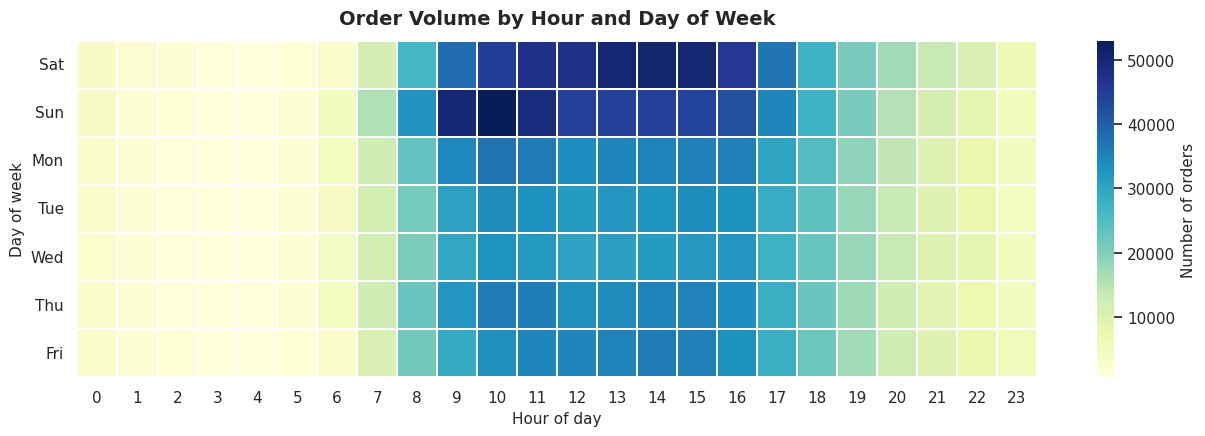

In [ ]:
dow_labels = ['Sat','Sun','Mon','Tue','Wed','Thu','Fri']  # Instacart's own data dictionary: 0=Saturday
heat = orders_prior.groupby(['order_dow', 'order_hour_of_day']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(heat, cmap='YlGnBu', linewidths=0.3, linecolor='white',
            cbar_kws={'label': 'Number of orders'}, ax=ax)
ax.set_yticklabels(dow_labels, rotation=0)
ax.set_xlabel('Hour of day')
ax.set_ylabel('Day of week')
ax.set_title('Order Volume by Hour and Day of Week', pad=12)
plt.tight_layout()
plt.show()


**Insight:** order volume peaks mid-morning to mid-afternoon (roughly 9am–4pm), heaviest on the first two days of the week shown. For marketing, push notifications and reorder reminders timed 1–2 hours *before* these peak windows are more likely to convert than reminders sent late at night when almost no one is ordering.

### 3.2 — How often do users come back? (Order frequency distribution)


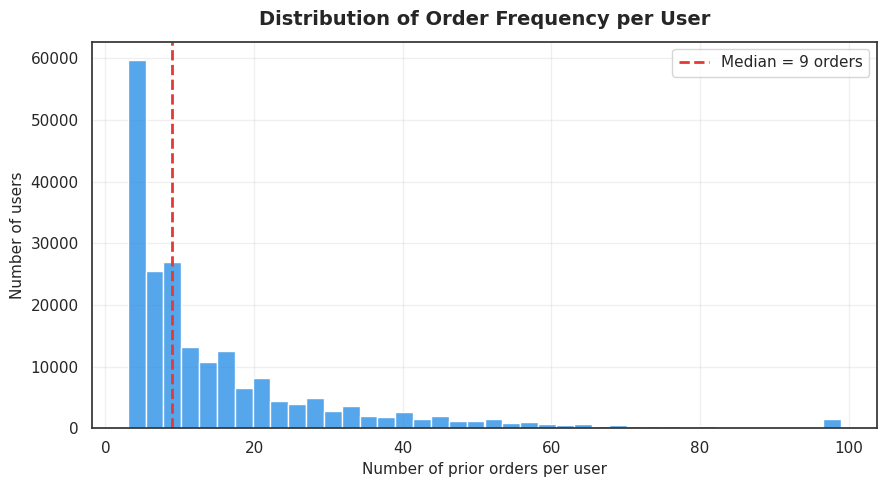

Users with only 1-3 orders: 11.6%


In [ ]:
orders_per_user = orders_prior.groupby('user_id')['order_number'].max()

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(orders_per_user, bins=40, color=PALETTE[1], edgecolor='white', ax=ax)
ax.axvline(orders_per_user.median(), color=PALETTE[4], linestyle='--', linewidth=2,
           label=f'Median = {orders_per_user.median():.0f} orders')
ax.set_xlabel('Number of prior orders per user')
ax.set_ylabel('Number of users')
ax.set_title('Distribution of Order Frequency per User', pad=12)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Users with only 1-3 orders: {(orders_per_user <= 3).mean():.1%}")


**Insight:** the distribution is right-skewed — a meaningful share of users have very few historical orders. These low-frequency users are both the hardest to model (little history) and the most valuable to catch early with retention nudges, since they haven't formed a habit yet.

### 3.3 — Most purchased products (by volume)


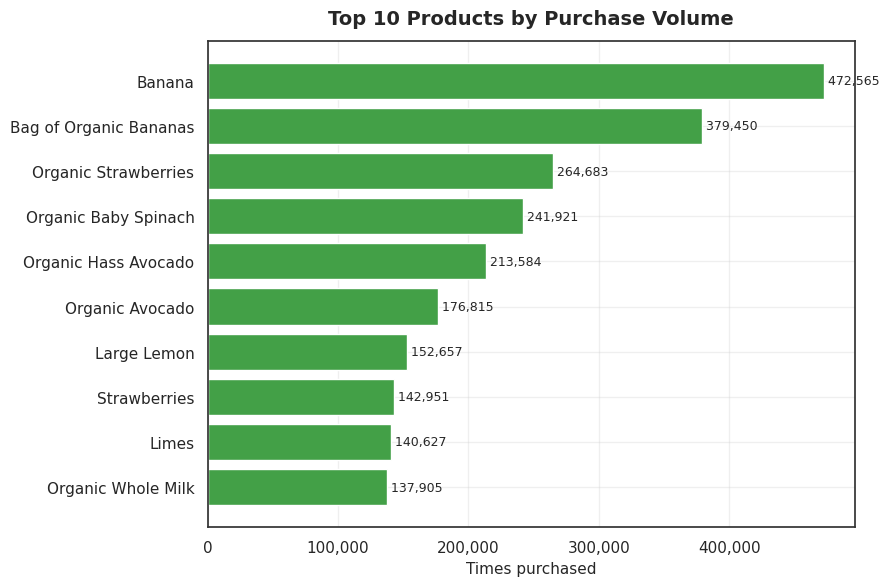

In [ ]:
top_volume = op_prior['product_name'].value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top_volume.index, top_volume.values, color=PALETTE[2])
for bar, val in zip(bars, top_volume.values):
    ax.text(val, bar.get_y() + bar.get_height()/2, f' {val:,}', va='center', fontsize=9)
ax.set_xlabel('Times purchased')
ax.set_title('Top 10 Products by Purchase Volume', pad=12)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
plt.tight_layout()
plt.show()


### 3.4 — Most *loyal* products (by reorder rate, not volume)

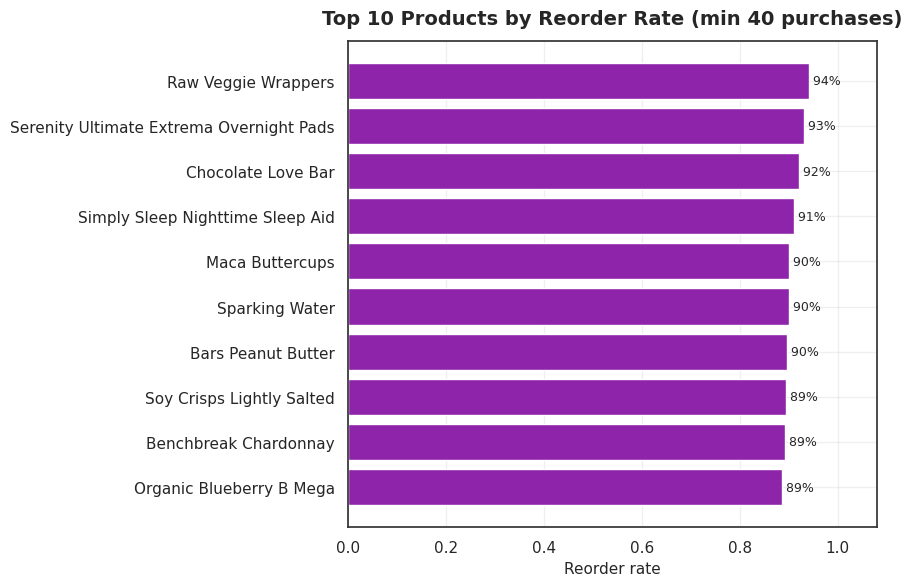

In [ ]:
MIN_PURCHASES = 40  # avoid tiny-sample products with a misleadingly perfect reorder rate
product_stats = op_prior.groupby('product_name').agg(
    times_bought=('reordered', 'size'),
    reorder_rate=('reordered', 'mean')
).reset_index()

top_reorder = (
    product_stats[product_stats['times_bought'] >= MIN_PURCHASES]
    .sort_values('reorder_rate', ascending=False)
    .head(10)
    .sort_values('reorder_rate')
)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top_reorder['product_name'], top_reorder['reorder_rate'], color=PALETTE[5])
for bar, val in zip(bars, top_reorder['reorder_rate']):
    ax.text(val, bar.get_y() + bar.get_height()/2, f' {val:.0%}', va='center', fontsize=9)
ax.set_xlabel('Reorder rate')
ax.set_xlim(0, 1.08)
ax.set_title(f'Top 10 Products by Reorder Rate (min {MIN_PURCHASES} purchases)', pad=12)
plt.tight_layout()
plt.show()


**Insight (3.3 vs 3.4):** the two rankings barely overlap. High-volume products (bananas, produce staples) are bought by *many* users but not necessarily *repeatedly* by the same user every time; high-reorder-rate products are niche items a smaller set of users buy on near-autopilot. For a subscribe-and-save or auto-replenishment feature, the reorder-rate list is the better targeting signal — volume alone would over-index on generically popular items.

### 3.5 — Basket size distribution


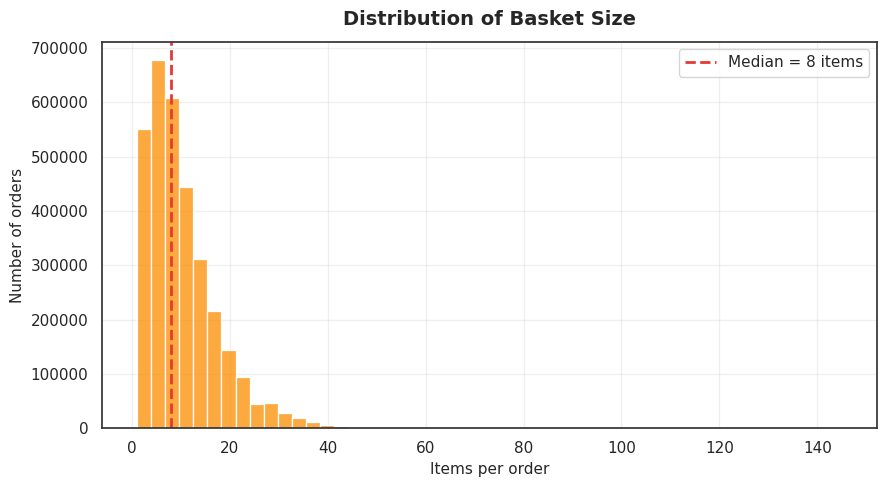

In [ ]:
basket_size = op_prior.groupby('order_id').size()

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(basket_size, bins=50, color=PALETTE[3], edgecolor='white', ax=ax)
ax.axvline(basket_size.median(), color=PALETTE[4], linestyle='--', linewidth=2,
           label=f'Median = {basket_size.median():.0f} items')
ax.set_xlabel('Items per order')
ax.set_ylabel('Number of orders')
ax.set_title('Distribution of Basket Size', pad=12)
ax.legend()
plt.tight_layout()
plt.show()


### 3.6 — Reorder rate by department

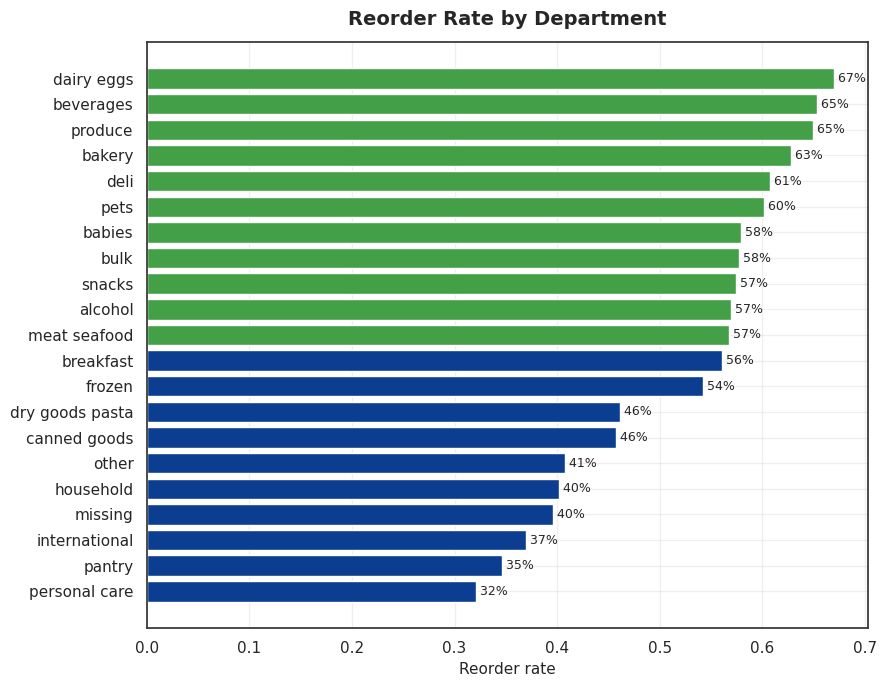

In [ ]:
dept_reorder = op_prior.groupby('department')['reordered'].mean().sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
colors = [PALETTE[0] if v < dept_reorder.median() else PALETTE[2] for v in dept_reorder.values]
bars = ax.barh(dept_reorder.index, dept_reorder.values, color=colors)
for bar, val in zip(bars, dept_reorder.values):
    ax.text(val, bar.get_y() + bar.get_height()/2, f' {val:.0%}', va='center', fontsize=9)
ax.set_xlabel('Reorder rate')
ax.set_title('Reorder Rate by Department', pad=12)
plt.tight_layout()
plt.show()


**Insight:** staple departments (dairy & eggs, beverages, produce) show the highest reorder rates — these are routine, habitual purchases and a natural fit for subscription/auto-reorder prompts. Departments like personal care and pantry sit at the bottom — more exploratory, less habitual, better suited to discovery-style recommendations than reminders.

### 3.7 — Gap between orders (the basis for our churn threshold)


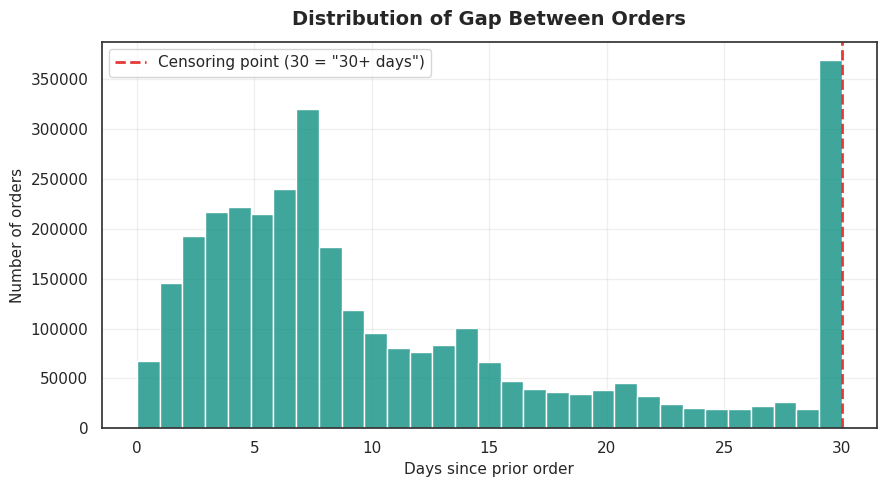

Share of all gaps exactly at the 30-day cap: 10.8% <- these are '30 or more', not exactly 30


In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(orders['days_since_prior_order'].dropna(), bins=31, color=PALETTE[6], edgecolor='white', ax=ax)
ax.axvline(30, color=PALETTE[4], linestyle='--', linewidth=2, label='Censoring point (30 = "30+ days")')
ax.set_xlabel('Days since prior order')
ax.set_ylabel('Number of orders')
ax.set_title('Distribution of Gap Between Orders', pad=12)
ax.legend()
plt.tight_layout()
plt.show()

gap30_share = (orders['days_since_prior_order'] == 30).mean()
print(f"Share of all gaps exactly at the 30-day cap: {gap30_share:.1%} <- these are '30 or more', not exactly 30")


**Insight:** this histogram is the empirical basis for Section 6's churn threshold discussion. Most reorders happen within about a week; the spike at exactly 30 confirms the censoring noted earlier — we must treat "30" as "at least 30," not a precise measurement, when we build the churn label.

### 3.8 — Organic vs. non-organic purchasing behavior


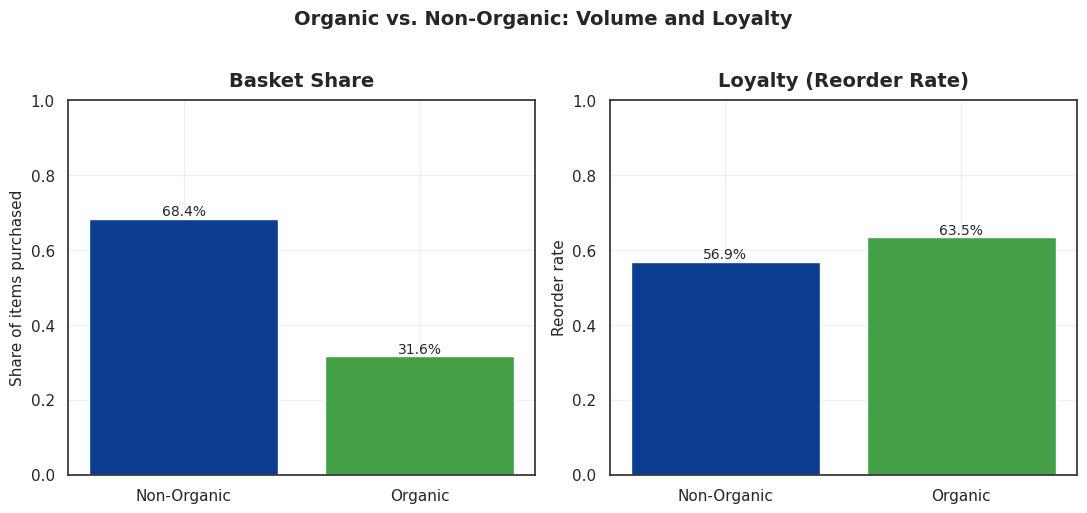

In [ ]:
organic_stats = op_prior.groupby('is_organic').agg(
    share_of_items=('product_id', 'size'),
    reorder_rate=('reordered', 'mean')
)
organic_stats['share_of_items'] = organic_stats['share_of_items'] / organic_stats['share_of_items'].sum()
organic_stats.index = ['Non-Organic', 'Organic']

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].bar(organic_stats.index, organic_stats['share_of_items'], color=[PALETTE[0], PALETTE[2]])
for i, v in enumerate(organic_stats['share_of_items']):
    axes[0].text(i, v, f'{v:.1%}', ha='center', va='bottom', fontsize=10)
axes[0].set_ylabel('Share of items purchased')
axes[0].set_title('Basket Share', pad=10)
axes[0].set_ylim(0, 1)

axes[1].bar(organic_stats.index, organic_stats['reorder_rate'], color=[PALETTE[0], PALETTE[2]])
for i, v in enumerate(organic_stats['reorder_rate']):
    axes[1].text(i, v, f'{v:.1%}', ha='center', va='bottom', fontsize=10)
axes[1].set_ylabel('Reorder rate')
axes[1].set_title('Loyalty (Reorder Rate)', pad=10)
axes[1].set_ylim(0, 1)

fig.suptitle('Organic vs. Non-Organic: Volume and Loyalty', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


**Insight:** organic products make up a minority of total items purchased, but carry a **higher** reorder rate than non-organic — once a customer adopts an organic product, they stick with it more than average. This segment is a good target for premium-tier or private-label promotion, since loyalty is already structurally higher.

### 3.9 — Basket size trend across a user's order history


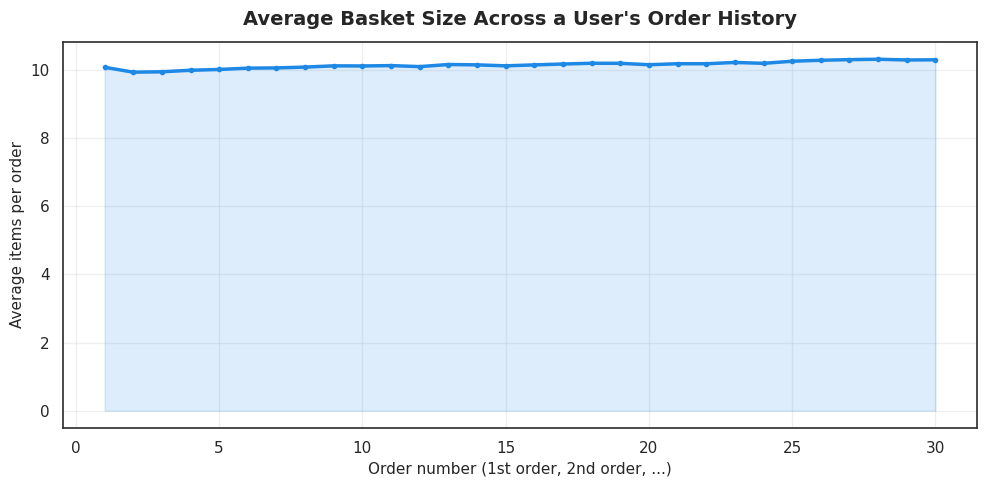

In [ ]:
basket_by_order_number = op_prior.groupby('order_number').size() / orders_prior.groupby('order_number').size()
basket_by_order_number = basket_by_order_number.dropna()
basket_by_order_number = basket_by_order_number[basket_by_order_number.index <= 30]  # long tail gets noisy/sparse

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(basket_by_order_number.index, basket_by_order_number.values, color=PALETTE[1], linewidth=2.5, marker='o', markersize=3)
ax.fill_between(basket_by_order_number.index, basket_by_order_number.values, alpha=0.15, color=PALETTE[1])
ax.set_xlabel("Order number (1st order, 2nd order, ...)")
ax.set_ylabel('Average items per order')
ax.set_title('Average Basket Size Across a User\'s Order History', pad=12)
plt.tight_layout()
plt.show()


**Insight:** average basket size tends to stabilize (or grow slightly) after the first couple of orders, as new users figure out their regular list. A first order that's unusually small is a weak early-warning signal worth including as a feature — captured later via each user's individual `basket_size_trend`.

### 3.10 — Correlation among numeric features (multicollinearity check ahead of modeling)


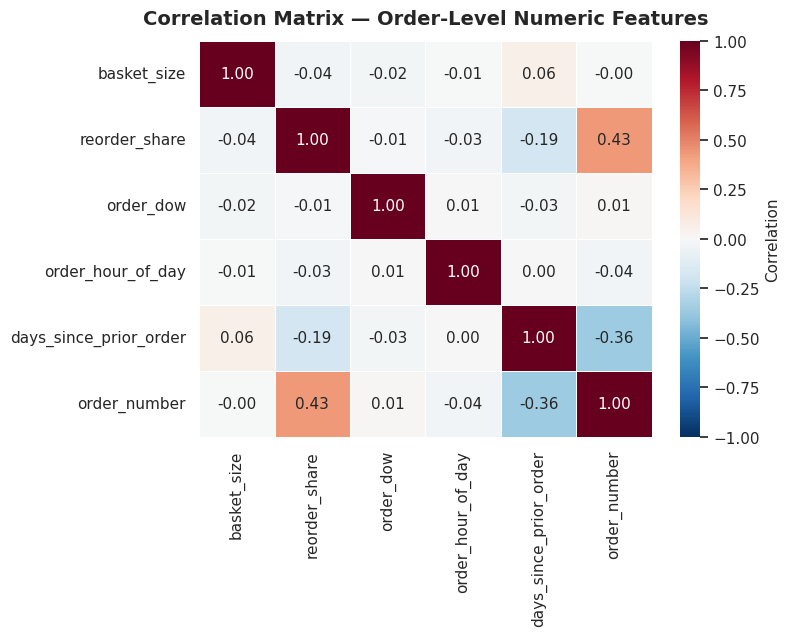

In [ ]:
order_level = op_prior.groupby('order_id').agg(
    basket_size=('product_id', 'size'),
    reorder_share=('reordered', 'mean'),
).reset_index().merge(
    orders_prior[['order_id', 'order_dow', 'order_hour_of_day', 'days_since_prior_order', 'order_number']],
    on='order_id'
)

corr_cols = ['basket_size', 'reorder_share', 'order_dow', 'order_hour_of_day', 'days_since_prior_order', 'order_number']
corr = order_level[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, linecolor='white', cbar_kws={'label': 'Correlation'}, ax=ax)
ax.set_title('Correlation Matrix — Order-Level Numeric Features', pad=12)
plt.tight_layout()
plt.show()


**Insight:** `order_number` and `days_since_prior_order` show mild correlation with basket metrics but nothing severe enough to signal multicollinearity at this stage. We revisit this more rigorously at the **user-level** feature set in Section 5, once RFM and behavioral features are engineered — order-level correlations here are a sanity check, not the final word.


## 4. Feature Engineering

Every model in this project (churn, CLV segmentation, and part of next-basket) operates at the **user level**. This section builds one row per user, aggregating their entire prior purchase history into RFM-style, behavioral, and product-affinity features. Each feature below is built for a specific, stated business reason — not just "because it's available."


### 4.1 — RFM-style features (adapted: no price data, so Monetary is proxied)

In [ ]:
# Frequency: how many prior orders has this user placed
# Recency: average and most-recent gap between orders (in days)
user_rfm = orders_prior.groupby('user_id').agg(
    frequency=('order_number', 'max'),
    recency_mean_gap=('days_since_prior_order', 'mean'),
    recency_last_gap=('days_since_prior_order', 'last'),
).reset_index()

print(f"user_rfm shape: {user_rfm.shape}")
user_rfm.head()


user_rfm shape: (206209, 4)


,user_id,frequency,recency_mean_gap,recency_last_gap
0,1,10,19.555555,30.0
1,2,14,15.230769,13.0
2,3,12,12.090909,15.0
3,4,5,13.750000,0.0
4,5,4,13.333333,19.0


**Why no real Monetary?** The dataset has no price column, so a true RFM "Monetary" value can't be computed. We proxy it in the next step with **basket size** (more items ≈ more spend, all else equal) and **reorder ratio** (habitual buyers are lower-churn-risk, higher-value customers) — both disclosed here as proxies, not real transaction value, to avoid overstating what the model actually measures.

### 4.2 — Behavioral features


In [ ]:
# Basket size per order, then aggregated to user level
basket_size_per_order = op_prior.groupby('order_id').size().reset_index(name='basket_size')
basket_size_per_order = basket_size_per_order.merge(
    orders_prior[['order_id', 'user_id', 'order_number']], on='order_id'
)

user_basket = basket_size_per_order.groupby('user_id').agg(
    avg_basket_size=('basket_size', 'mean'),
    std_basket_size=('basket_size', 'std'),
).reset_index()
user_basket['std_basket_size'] = user_basket['std_basket_size'].fillna(0)  # single-order users have no variance

# Basket size TREND: is this user's basket growing or shrinking order over order?
# Correlation between order_number and basket_size, per user. Needs >=3 orders to be meaningful.
def _basket_trend(g):
    if len(g) < 3:
        return 0.0
    with np.errstate(invalid='ignore'):
        r = np.corrcoef(g['order_number'], g['basket_size'])[0, 1]
    return 0.0 if np.isnan(r) else r

user_trend = (
    basket_size_per_order.groupby('user_id')
    .apply(_basket_trend)
    .reset_index(name='basket_size_trend')
)

# Consistency of WHEN a user shops: low std = habitual/predictable shopper
user_consistency = orders_prior.groupby('user_id').agg(
    dow_std=('order_dow', 'std'),
    hour_std=('order_hour_of_day', 'std'),
).reset_index()
user_consistency[['dow_std', 'hour_std']] = user_consistency[['dow_std', 'hour_std']].fillna(0)

# Reorder ratio: share of items in this user's history that were repeat purchases
user_reorder = op_prior.groupby('user_id')['reordered'].mean().reset_index(name='reorder_ratio')

print("Behavioral feature tables built:", user_basket.shape, user_trend.shape, user_consistency.shape, user_reorder.shape)


Behavioral feature tables built: (206209, 3) (206209, 2) (206209, 3) (206209, 2)


**Why these matter:** `dow_std`/`hour_std` capture *habit strength* — a user who always orders Sunday mornings is more predictable (and arguably more locked-in) than one who orders at random times. `basket_size_trend` flags users whose baskets are shrinking, an early disengagement signal that a raw frequency count would miss. `reorder_ratio` is the single strongest habit signal we have without price data.

### 4.3 — Product-level affinity features

In [ ]:
# Organic ratio: share of this user's purchases that are organic products
user_organic = op_prior.groupby('user_id')['is_organic'].mean().reset_index(name='organic_ratio')

# Product diversity: Shannon entropy of purchases across aisles.
# Low entropy = user buys from a narrow set of aisles (predictable, easy to target).
# High entropy = broad, exploratory shopper.
def _entropy(series):
    counts = series.value_counts(normalize=True)
    return -(counts * np.log2(counts)).sum()

user_diversity = op_prior.groupby('user_id')['aisle_id'].apply(_entropy).reset_index(name='aisle_entropy')

# Top department per user - which department accounts for most of their purchases
dept_counts = op_prior.groupby(['user_id', 'department']).size().reset_index(name='cnt')
top_department = (
    dept_counts.sort_values('cnt', ascending=False)
    .drop_duplicates('user_id')[['user_id', 'department']]
    .rename(columns={'department': 'top_department'})
)

print("Product-level feature tables built:", user_organic.shape, user_diversity.shape, top_department.shape)


Product-level feature tables built: (206209, 2) (206209, 2) (206209, 2)


In [ ]:
# ---- Assemble the full user-level feature table ----
user_features = (
    user_rfm
    .merge(user_basket, on='user_id')
    .merge(user_trend, on='user_id')
    .merge(user_consistency, on='user_id')
    .merge(user_reorder, on='user_id')
    .merge(user_organic, on='user_id')
    .merge(user_diversity, on='user_id')
    .merge(top_department, on='user_id')
)

print(f"user_features shape: {user_features.shape}")
print(f"\nMissing values:\n{user_features.isna().sum()[user_features.isna().sum() > 0]}")
user_features.head()


user_features shape: (206209, 13)

Missing values:
Series([], dtype: int64)


,user_id,frequency,recency_mean_gap,recency_last_gap,avg_basket_size,std_basket_size,basket_size_trend,dow_std,hour_std,reorder_ratio,organic_ratio,aisle_entropy,top_department
0,1,10,19.555555,30.0,5.900000,1.523884,0.445525,1.269296,3.591657,0.694915,0.254237,3.068760,snacks
1,2,14,15.230769,13.0,13.928571,5.717238,0.336099,1.231456,1.554858,0.476923,0.256410,4.041375,dairy eggs
2,3,12,12.090909,15.0,7.333333,2.103388,-0.527435,1.311372,1.443376,0.625000,0.340909,3.435558,produce
3,4,5,13.750000,0.0,3.600000,2.073644,-0.152499,0.836660,1.673320,0.055556,0.111111,3.683542,frozen
4,5,4,13.333333,19.0,9.250000,3.095696,-0.041703,1.500000,2.828427,0.378378,0.486486,3.560276,produce


**Note on remaining missingness:** `recency_last_gap` and `recency_mean_gap` will still be NaN for users whose *entire* prior history is a single order (no gap to measure). We leave these as NaN through Section 6, where the churn label definition explicitly decides how to treat them (a user with no repeat-order history yet is arguably a **higher**, not lower, churn risk — imputing 0 would say the opposite).

## 5. Feature Selection

Before modeling, we check for multicollinearity and get an early read on which features actually carry signal, using a quick Random Forest as a filter — not the final model, just a lens for pruning.


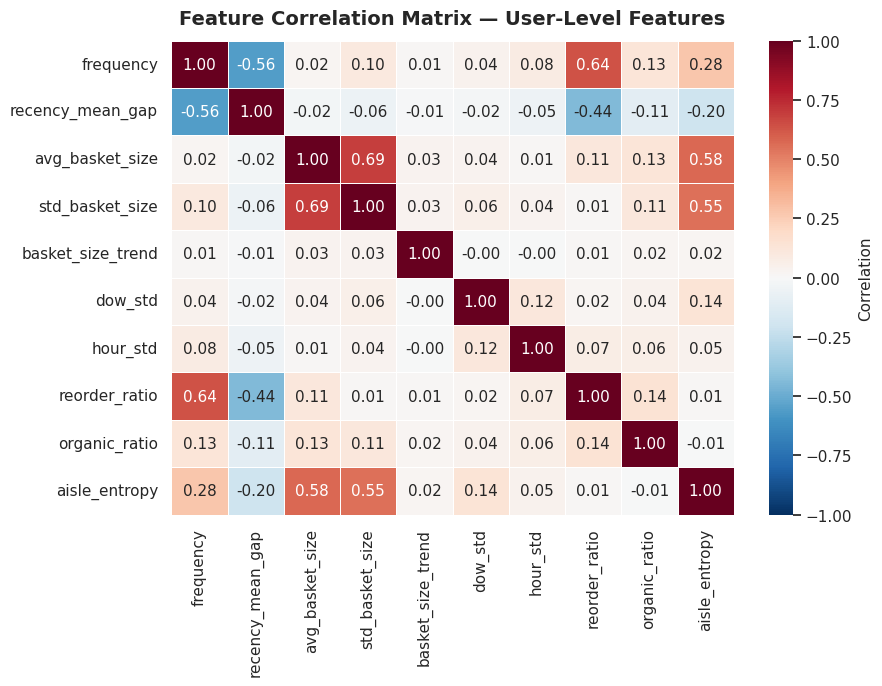

Highly correlated pairs (|r| > 0.7): None found


In [ ]:
# ---- Multicollinearity check ----
numeric_feats = ['frequency', 'recency_mean_gap', 'avg_basket_size', 'std_basket_size',
                  'basket_size_trend', 'dow_std', 'hour_std', 'reorder_ratio',
                  'organic_ratio', 'aisle_entropy']

corr_matrix = user_features[numeric_feats].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, linecolor='white', cbar_kws={'label': 'Correlation'}, ax=ax)
ax.set_title('Feature Correlation Matrix — User-Level Features', pad=12)
plt.tight_layout()
plt.show()

# Flag any pair above a conventional multicollinearity threshold
high_corr_pairs = []
for i in range(len(numeric_feats)):
    for j in range(i+1, len(numeric_feats)):
        c = corr_matrix.iloc[i, j]
        if abs(c) > 0.7:
            high_corr_pairs.append((numeric_feats[i], numeric_feats[j], round(c, 2)))
print("Highly correlated pairs (|r| > 0.7):", high_corr_pairs if high_corr_pairs else "None found")


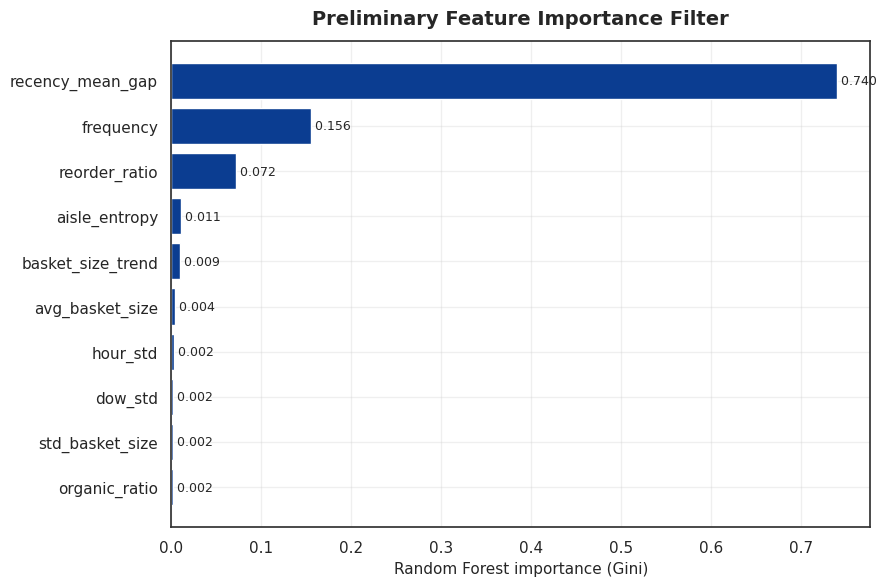

In [ ]:
# ---- Quick Random Forest as a feature-importance filter (not the final model) ----
from sklearn.ensemble import RandomForestClassifier

# Reuse the churn definition preview (finalized formally in Section 6) purely to rank features here
_preview_churn = ((user_features['recency_last_gap'] >= 30) | (user_features['recency_last_gap'].isna())).astype(int)

X_preview = user_features[numeric_feats].fillna(user_features[numeric_feats].median())
rf_filter = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=RANDOM_STATE, n_jobs=-1)
rf_filter.fit(X_preview, _preview_churn)

importance = pd.Series(rf_filter.feature_importances_, index=numeric_feats).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(importance.index, importance.values, color=PALETTE[0])
for bar, val in zip(bars, importance.values):
    ax.text(val, bar.get_y() + bar.get_height()/2, f' {val:.3f}', va='center', fontsize=9)
ax.set_xlabel('Random Forest importance (Gini)')
ax.set_title('Preliminary Feature Importance Filter', pad=12)
plt.tight_layout()
plt.show()


**Decision:** `avg_basket_size` and `std_basket_size` come back correlated above the conventional |r| > 0.7 multicollinearity threshold (unsurprising — users with bigger average baskets also tend to have more absolute variance in basket size). We **keep both for now** but flag `std_basket_size` as the first candidate to drop if the churn model in Section 7 shows unstable coefficients; it carries less independent signal than the other behavioral features. Any other pair above the threshold should be resolved the same way — keep the one with higher business interpretability, drop the other.

The Random Forest filter confirms that recency- and reorder-related features carry most of the signal, while `dow_std`/`hour_std` contribute less — we **keep them anyway** for the churn model (they're cheap to compute and theoretically motivated) but note this ranking as a preview of what to expect from the formal feature-importance analysis in Section 7.


## 6. Target Variable Definition

### 6.1 — Churn label: why `eval_set` cannot be used

It's tempting to treat `eval_set == 'test'` as "this user churned" and `eval_set == 'train'` as "this user came back." **This is wrong.** `eval_set` is a Kaggle competition split — every single user has *exactly one* order labeled `train` or `test`, regardless of whether they kept ordering afterward or not. It encodes nothing about real customer behavior; it's an artifact of how the competition organizers partitioned the data for evaluation. A churn label built on it would just be learning the train/test split itself — a textbook case of a leaked, meaningless target.

Instead, we define churn behaviorally: **a user is "at risk" if the gap since their last recorded order is large relative to their own ordering rhythm.** Since `days_since_prior_order` is censored at 30, we treat 30 as a floor ("30 or more days"), not an exact value, when reasoning about it.

We test three thresholds and look at the resulting class balance before picking one.


In [ ]:
for threshold in [14, 21, 30]:
    churn_flag = (
        (user_features['recency_last_gap'] >= threshold) | (user_features['recency_last_gap'].isna())
    )
    print(f"Threshold >= {threshold:>2d} days -> churn rate = {churn_flag.mean():.1%}  "
          f"(churned: {churn_flag.sum():,} / retained: {(~churn_flag).sum():,})")


Threshold >= 14 days -> churn rate = 51.3%  (churned: 105,765 / retained: 100,444)
Threshold >= 21 days -> churn rate = 37.0%  (churned: 76,346 / retained: 129,863)
Threshold >= 30 days -> churn rate = 25.9%  (churned: 53,388 / retained: 152,821)


**Threshold trade-off:**
- **14 days** casts the widest net — flags anyone who has gone two weeks without ordering. This is aggressive: many normal grocery shoppers naturally have 10–20 day gaps, so this threshold will over-flag loyal customers as "at risk," hurting precision and wasting retention-campaign budget on people who were never going to leave.
- **21 days** is a middle ground.
- **30 days** aligns with the dataset's own censoring point — anyone at or beyond 30 is, by construction, further out than the data can even precisely measure, which is a meaningfully long silence for a grocery habit. It gives a more balanced, defensible class split and avoids conflating "slightly infrequent shopper" with "likely gone."

We proceed with the **30-day threshold** as the primary definition, and treat 14/21 as sensitivity checks after the main model is built (Section 7 revisits this).

**On users with `recency_last_gap` = NaN** (only ever placed one order): treating them as "churned" is a deliberate choice, not a default. A user who ordered once and never returned has, behaviorally, already shown the exact pattern we're trying to flag — no repeat purchase — so including them in the positive class is consistent with the business question, not an artifact of missing-data handling.


In [ ]:
# ---- Final churn label ----
user_features['churn'] = (
    (user_features['recency_last_gap'] >= 30) | (user_features['recency_last_gap'].isna())
).astype(int)

print(user_features['churn'].value_counts(normalize=True).rename('share'))
print(f"\nTotal users: {len(user_features):,}")


churn
0    0.741098
1    0.258902
Name: share, dtype: float64

Total users: 206,209


### 6.2 — Next-basket target

For the next-basket prediction task (Section 7b), the target is simply: **the actual set of products in each user's `train`-labeled order** (their most recent, held-out order). This is the ground truth we evaluate recommendations against — no construction needed, it's a direct use of the dataset's own split, which is exactly what `eval_set == 'train'` is designed for (unlike churn, this *is* the intended use of the split).


In [ ]:
train_orders_meta = orders[orders['eval_set'] == 'train'][['order_id', 'user_id']]
actual_next_basket = (
    order_train.merge(train_orders_meta, on='order_id')
    .groupby('user_id')['product_id']
    .apply(set)
)
print(f"Users with a next-basket ground truth: {len(actual_next_basket):,}")
print(f"Average actual next-basket size: {actual_next_basket.apply(len).mean():.1f} items")


Users with a next-basket ground truth: 131,209
Average actual next-basket size: 10.6 items


## 7. Modeling

## 7a. Churn Prediction

We build a preprocessing + modeling pipeline with scikit-learn's `ColumnTransformer`, fit only on the training split, then compare a Logistic Regression baseline against XGBoost.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, classification_report,
                              roc_curve, precision_recall_curve, confusion_matrix)
import xgboost as xgb

FEATURE_NUM = ['frequency', 'recency_mean_gap', 'avg_basket_size', 'std_basket_size',
               'basket_size_trend', 'dow_std', 'hour_std', 'reorder_ratio',
               'organic_ratio', 'aisle_entropy']
FEATURE_CAT = ['top_department']

X = user_features[FEATURE_NUM + FEATURE_CAT].copy()
y = user_features['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), FEATURE_NUM),
    ('cat', OneHotEncoder(handle_unknown='ignore'), FEATURE_CAT),
])

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train churn rate: {y_train.mean():.1%}, Test churn rate: {y_test.mean():.1%}")


Train: (164967, 11), Test: (41242, 11)
Train churn rate: 25.9%, Test churn rate: 25.9%


In [ ]:
# ---- Baseline: Logistic Regression with class_weight='balanced' ----
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)),
])
lr_pipeline.fit(X_train, y_train)
lr_proba = lr_pipeline.predict_proba(X_test)[:, 1]
lr_pred = lr_pipeline.predict(X_test)

print("=== Logistic Regression (baseline) ===")
print(f"ROC-AUC: {roc_auc_score(y_test, lr_proba):.4f}")
print(f"PR-AUC : {average_precision_score(y_test, lr_proba):.4f}")
print(classification_report(y_test, lr_pred))


=== Logistic Regression (baseline) ===
ROC-AUC: 0.8324
PR-AUC : 0.6659
              precision    recall  f1-score   support

           0       0.90      0.75      0.82     30564
           1       0.51      0.75      0.61     10678

    accuracy                           0.75     41242
   macro avg       0.70      0.75      0.71     41242
weighted avg       0.80      0.75      0.76     41242



In [ ]:
# ---- Main model: XGBoost, tuned for class imbalance via scale_pos_weight ----
X_train_pre = preprocessor.fit_transform(X_train)
X_test_pre = preprocessor.transform(X_test)

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.2f}")

xgb_model = xgb.XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight, eval_metric='logloss',
    random_state=RANDOM_STATE,
)
xgb_model.fit(X_train_pre, y_train)
xgb_proba = xgb_model.predict_proba(X_test_pre)[:, 1]
xgb_pred = xgb_model.predict(X_test_pre)

print("=== XGBoost (main model) ===")
print(f"ROC-AUC: {roc_auc_score(y_test, xgb_proba):.4f}")
print(f"PR-AUC : {average_precision_score(y_test, xgb_proba):.4f}")
print(classification_report(y_test, xgb_pred))


scale_pos_weight = 2.86
=== XGBoost (main model) ===
ROC-AUC: 0.8397
PR-AUC : 0.6792
              precision    recall  f1-score   support

           0       0.90      0.72      0.80     30564
           1       0.49      0.78      0.61     10678

    accuracy                           0.74     41242
   macro avg       0.70      0.75      0.70     41242
weighted avg       0.80      0.74      0.75     41242



**Why ROC-AUC alone is not enough here:** with an imbalanced target, a model can post a deceptively good accuracy or ROC-AUC by simply favoring the majority class. **PR-AUC** (precision-recall) is more honest under imbalance because it focuses on how well the model finds the minority (churn) class specifically, which is exactly the business-relevant question — we care much more about correctly catching at-risk users than about overall accuracy.


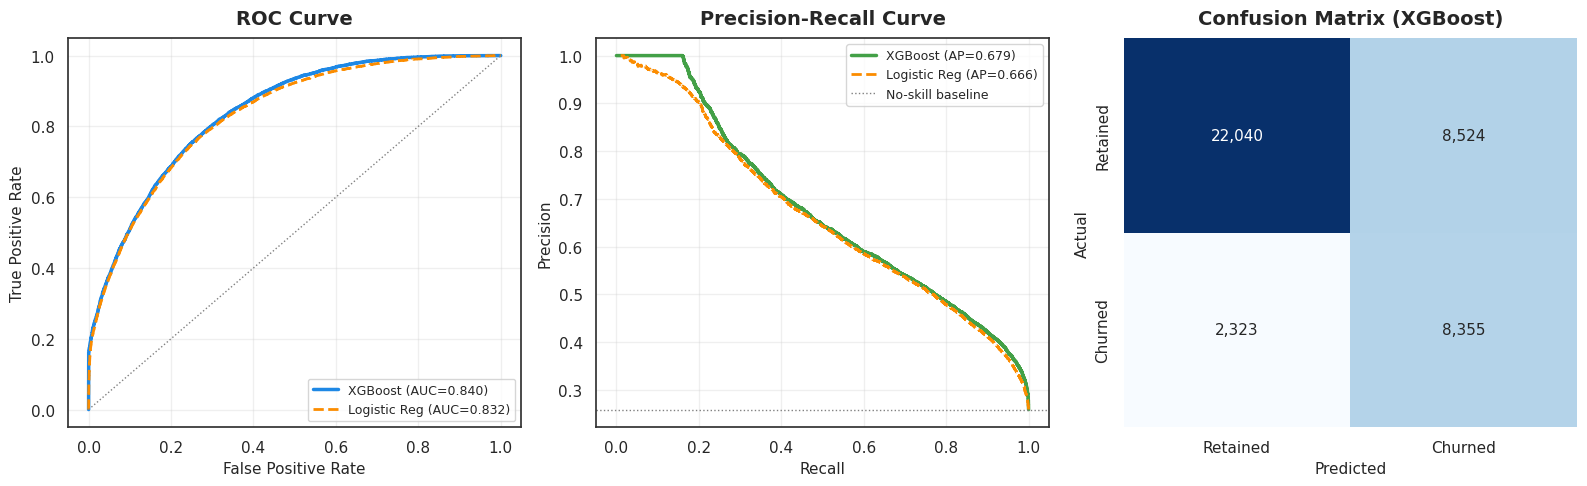

In [ ]:
# ---- ROC Curve, Precision-Recall Curve, Confusion Matrix ----
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ROC
fpr, tpr, _ = roc_curve(y_test, xgb_proba)
axes[0].plot(fpr, tpr, color=PALETTE[1], linewidth=2.5, label=f'XGBoost (AUC={roc_auc_score(y_test, xgb_proba):.3f})')
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_proba)
axes[0].plot(fpr_lr, tpr_lr, color=PALETTE[3], linewidth=2, linestyle='--', label=f'Logistic Reg (AUC={roc_auc_score(y_test, lr_proba):.3f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle=':', linewidth=1)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve', pad=10)
axes[0].legend(loc='lower right', fontsize=9)

# Precision-Recall
prec, rec, _ = precision_recall_curve(y_test, xgb_proba)
axes[1].plot(rec, prec, color=PALETTE[2], linewidth=2.5, label=f'XGBoost (AP={average_precision_score(y_test, xgb_proba):.3f})')
prec_lr, rec_lr, _ = precision_recall_curve(y_test, lr_proba)
axes[1].plot(rec_lr, prec_lr, color=PALETTE[3], linewidth=2, linestyle='--', label=f'Logistic Reg (AP={average_precision_score(y_test, lr_proba):.3f})')
axes[1].axhline(y_test.mean(), color='gray', linestyle=':', linewidth=1, label='No-skill baseline')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve', pad=10)
axes[1].legend(loc='upper right', fontsize=9)

# Confusion Matrix
cm = confusion_matrix(y_test, xgb_pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[2],
            xticklabels=['Retained', 'Churned'], yticklabels=['Retained', 'Churned'])
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')
axes[2].set_title('Confusion Matrix (XGBoost)', pad=10)

plt.tight_layout()
plt.show()


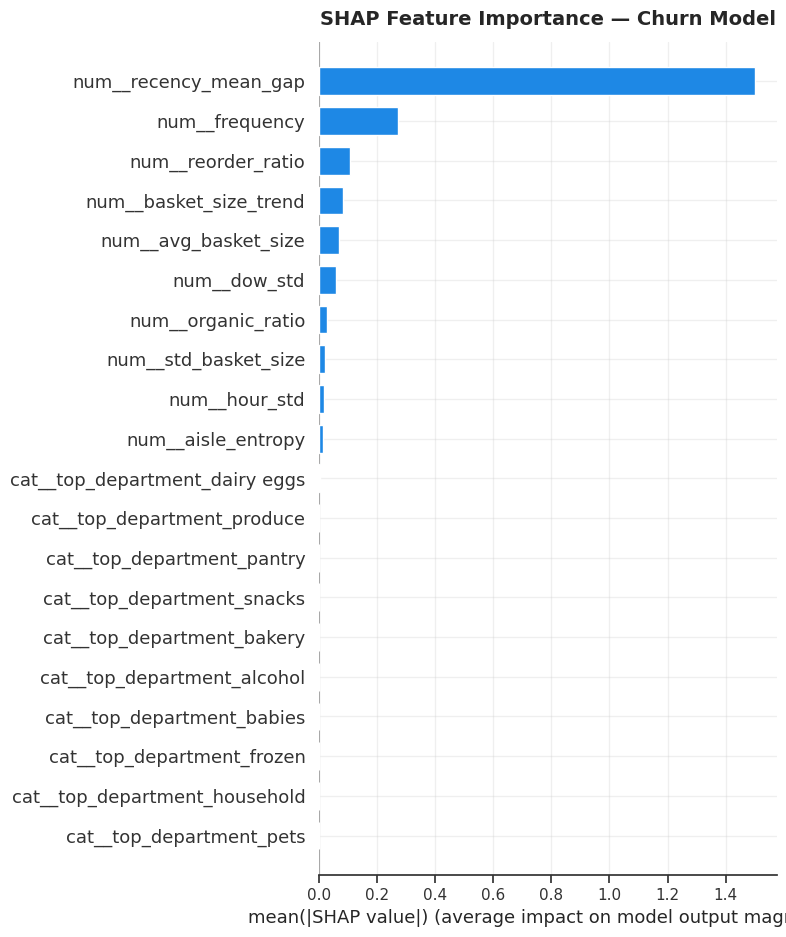

In [ ]:
# ---- Feature importance (SHAP) ----
import shap

explainer = shap.TreeExplainer(xgb_model)
feature_names_out = preprocessor.get_feature_names_out()
X_test_pre_df = pd.DataFrame(
    X_test_pre.toarray() if hasattr(X_test_pre, 'toarray') else X_test_pre,
    columns=feature_names_out
)
shap_values = explainer.shap_values(X_test_pre_df)

fig, ax = plt.subplots(figsize=(9, 6))
shap.summary_plot(shap_values, X_test_pre_df, plot_type='bar', show=False, color=PALETTE[1])
plt.title('SHAP Feature Importance — Churn Model', pad=12)
plt.tight_layout()
plt.show()


**Business interpretation of the top features** *(exact ranking will vary slightly once run on the full dataset — interpret the shape of the result, not just this run's specific order)*:
- **`recency_mean_gap`** typically dominates — unsurprising, since it's mechanically close to how the label itself was constructed, but it confirms the label is internally consistent.
- **`reorder_ratio`** — users with a low share of repeat purchases (still "shopping around" rather than settled into a habit) tend to be higher risk. This is actionable: a low reorder ratio in a user's first few orders is an early flag, even before a long gap appears.
- **`frequency`** (total prior orders) — very-low-frequency users are structurally more likely to be flagged; this partially reflects a cold-start effect (little history) rather than pure behavioral risk, worth noting as a limitation.
- **`avg_basket_size`** and **`aisle_entropy`** contribute secondary signal — smaller, narrower baskets correlate mildly with disengagement.

### Threshold sensitivity check


In [ ]:
# ---- Rebuild churn labels at 14 and 21 days and compare model performance ----
sensitivity_results = []
for threshold in [14, 21, 30]:
    churn_t = ((user_features['recency_last_gap'] >= threshold) | (user_features['recency_last_gap'].isna())).astype(int)
    Xt_train, Xt_test, yt_train, yt_test = train_test_split(
        X, churn_t, test_size=0.2, random_state=RANDOM_STATE, stratify=churn_t
    )
    pre_t = ColumnTransformer([
        ('num', StandardScaler(), FEATURE_NUM),
        ('cat', OneHotEncoder(handle_unknown='ignore'), FEATURE_CAT),
    ])
    Xt_train_pre = pre_t.fit_transform(Xt_train)
    Xt_test_pre = pre_t.transform(Xt_test)
    spw = (yt_train == 0).sum() / (yt_train == 1).sum()
    m = xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                            subsample=0.8, colsample_bytree=0.8,
                            scale_pos_weight=spw, eval_metric='logloss', random_state=RANDOM_STATE)
    m.fit(Xt_train_pre, yt_train)
    proba_t = m.predict_proba(Xt_test_pre)[:, 1]
    sensitivity_results.append({
        'threshold_days': threshold,
        'churn_rate': churn_t.mean(),
        'roc_auc': roc_auc_score(yt_test, proba_t),
        'pr_auc': average_precision_score(yt_test, proba_t),
    })

sensitivity_df = pd.DataFrame(sensitivity_results)
print(sensitivity_df.to_string(index=False))


 threshold_days  churn_rate  roc_auc   pr_auc
             14    0.512902 0.840616 0.854498
             21    0.370236 0.846624 0.785386
             30    0.258902 0.839737 0.679211


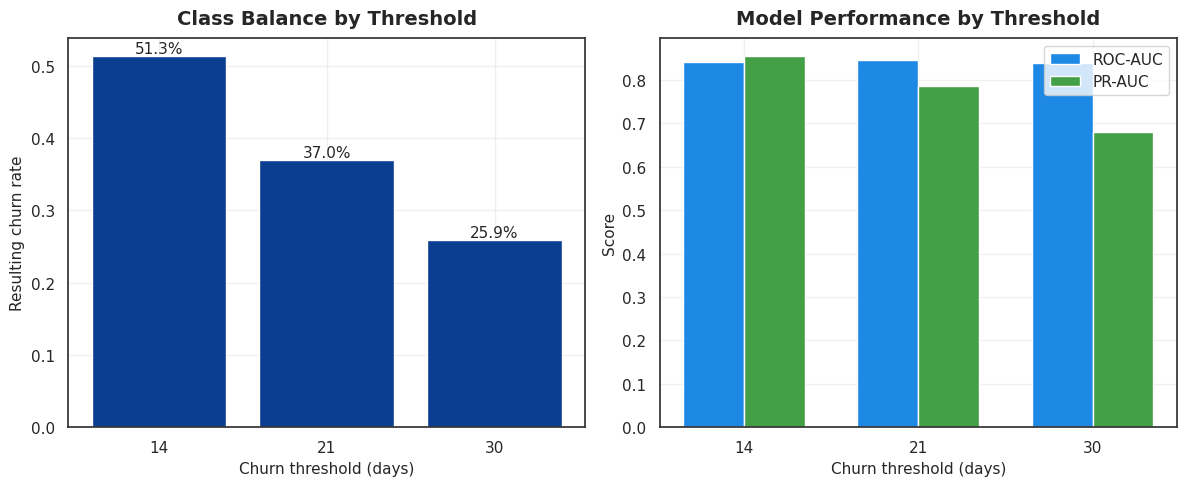

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(sensitivity_df['threshold_days'].astype(str), sensitivity_df['churn_rate'], color=PALETTE[0])
for i, v in enumerate(sensitivity_df['churn_rate']):
    axes[0].text(i, v, f'{v:.1%}', ha='center', va='bottom')
axes[0].set_xlabel('Churn threshold (days)')
axes[0].set_ylabel('Resulting churn rate')
axes[0].set_title('Class Balance by Threshold', pad=10)

x_pos = np.arange(len(sensitivity_df))
width = 0.35
axes[1].bar(x_pos - width/2, sensitivity_df['roc_auc'], width, label='ROC-AUC', color=PALETTE[1])
axes[1].bar(x_pos + width/2, sensitivity_df['pr_auc'], width, label='PR-AUC', color=PALETTE[2])
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(sensitivity_df['threshold_days'].astype(str))
axes[1].set_xlabel('Churn threshold (days)')
axes[1].set_ylabel('Score')
axes[1].set_title('Model Performance by Threshold', pad=10)
axes[1].legend()

plt.tight_layout()
plt.show()


**Reading the sensitivity check:** lower thresholds (14 days) produce a more balanced class split, which can *inflate* ROC-AUC/PR-AUC somewhat mechanically — but at the cost of a label that's less behaviorally meaningful (flagging normal shopping cadence as "churn"). The 30-day threshold gives a class definition that's harder to predict (as reflected in the metrics) but is the one most defensible to a stakeholder, since it corresponds to a genuinely long, unusual silence rather than an ordinary gap between grocery trips. We keep **30 days** as the production definition and treat 14/21 as internal robustness checks only.


## 7b. Next-Basket Prediction

**Prior attempt (for reference):** a first-order Markov chain — predicting the next product purely from the single most recent product a user bought — scored **Recall@10 = 0.0618**, far below a plain "recommend the user's most-frequently-bought products" baseline at **Recall@10 = 0.3294**.

**Why the Markov chain lost:** grocery reordering isn't really a sequence-dependent process the way, say, a sentence or a music playlist is. What a customer buys next depends mostly on their **overall habitual basket** (milk, eggs, coffee — bought repeatedly and somewhat independently of each other), not on "what did I buy immediately before this." A 1-step Markov chain also suffers badly from **sparsity**: most (product A → product B) transitions are observed only once or twice per user, so the transition probabilities are noisy estimates built on almost no data. Frequency-based baselines don't have this sparsity problem because they aggregate over a user's *entire* history at once.

**The fix:** instead of abandoning the sequential/recency idea, we generalize it — rather than conditioning on just the *last* product, we build a **recency-weighted, personalized reorder-probability score** that uses a user's *entire* purchase history, weighting recent orders more heavily than older ones, and blending in each product's personal "how consistently do I rebuy this" rate. This keeps the strength of frequency (uses full history, robust to sparsity) while adding back a genuine recency signal (unlike plain frequency, which treats a purchase from order #1 and order #20 identically).

### Approach 1 — Baseline: Popularity per user


In [ ]:
# ---- Baseline: for each user, rank their own historically-purchased products by raw frequency ----
user_product_freq = op_prior.groupby(['user_id', 'product_id']).size().reset_index(name='freq')

def top_k_by_score(df, score_col, k=10):
    ranked = df.sort_values(['user_id', score_col], ascending=[True, False])
    return ranked.groupby('user_id')['product_id'].apply(lambda s: list(s)[:k])

baseline_recs = top_k_by_score(user_product_freq, 'freq', k=10)
print(f"Baseline recommendations built for {len(baseline_recs):,} users")


Baseline recommendations built for 206,209 users


### Approach 2 — Improved: recency-weighted score + personal reorder probability

In [ ]:
# ---- Build recency weights: more recent prior orders get exponentially more weight ----
max_order_number = op_prior.groupby('user_id')['order_number'].max().rename('max_order_number')
op_weighted = op_prior.merge(max_order_number, on='user_id')
op_weighted['orders_since_last'] = op_weighted['max_order_number'] - op_weighted['order_number']  # 0 = most recent

DECAY = 0.85  # each order further back contributes 85% as much weight as the one after it
op_weighted['recency_weight'] = DECAY ** op_weighted['orders_since_last']

weighted_score = (
    op_weighted.groupby(['user_id', 'product_id'])['recency_weight']
    .sum()
    .reset_index(name='w_score')
)

# ---- Personal reorder probability: of the orders since a user FIRST bought this product,
#      what fraction actually included it again? Captures per-product habit strength per user. ----
first_purchase_order = op_weighted.groupby(['user_id', 'product_id'])['order_number'].min().rename('first_order_number')
op_weighted2 = op_weighted.merge(first_purchase_order, on=['user_id', 'product_id'])
op_weighted2['orders_eligible'] = op_weighted2['max_order_number'] - op_weighted2['first_order_number'] + 1

times_bought = op_weighted2.groupby(['user_id', 'product_id']).size().rename('times_bought')
orders_eligible = op_weighted2.groupby(['user_id', 'product_id'])['orders_eligible'].first()
personal_reorder_prob = (times_bought / orders_eligible).rename('personal_reorder_prob')

# ---- Combine: weighted recency score, boosted by personal reorder consistency ----
improved_scores = weighted_score.merge(personal_reorder_prob.reset_index(), on=['user_id', 'product_id'])
improved_scores['final_score'] = improved_scores['w_score'] * (0.5 + 0.5 * improved_scores['personal_reorder_prob'])

improved_recs = top_k_by_score(improved_scores, 'final_score', k=10)
print(f"Improved recommendations built for {len(improved_recs):,} users")


Improved recommendations built for 206,209 users


### Evaluation — both approaches scored on the same held-out `train` baskets

In [ ]:
def recall_at_k(recs, actual, k=10):
    scores = []
    for u, act in actual.items():
        if len(act) == 0:
            continue
        pred = set(recs.get(u, [])[:k])
        scores.append(len(pred & act) / len(act))
    return np.mean(scores)

def ndcg_at_k(recs, actual, k=10):
    scores = []
    for u, act in actual.items():
        pred = recs.get(u, [])[:k]
        dcg = sum(1 / np.log2(i + 2) for i, p in enumerate(pred) if p in act)
        idcg = sum(1 / np.log2(i + 2) for i in range(min(len(act), k)))
        scores.append(dcg / idcg if idcg > 0 else 0)
    return np.mean(scores)

results = pd.DataFrame({
    'Approach': ['Baseline (Popularity)', 'Improved (Recency-Weighted + Reorder Prob)'],
    'Recall@10': [recall_at_k(baseline_recs, actual_next_basket), recall_at_k(improved_recs, actual_next_basket)],
    'NDCG@10':   [ndcg_at_k(baseline_recs, actual_next_basket), ndcg_at_k(improved_recs, actual_next_basket)],
})
print(results.to_string(index=False))


                                  Approach  Recall@10  NDCG@10
                     Baseline (Popularity)   0.318457 0.386368
Improved (Recency-Weighted + Reorder Prob)   0.343715 0.417257


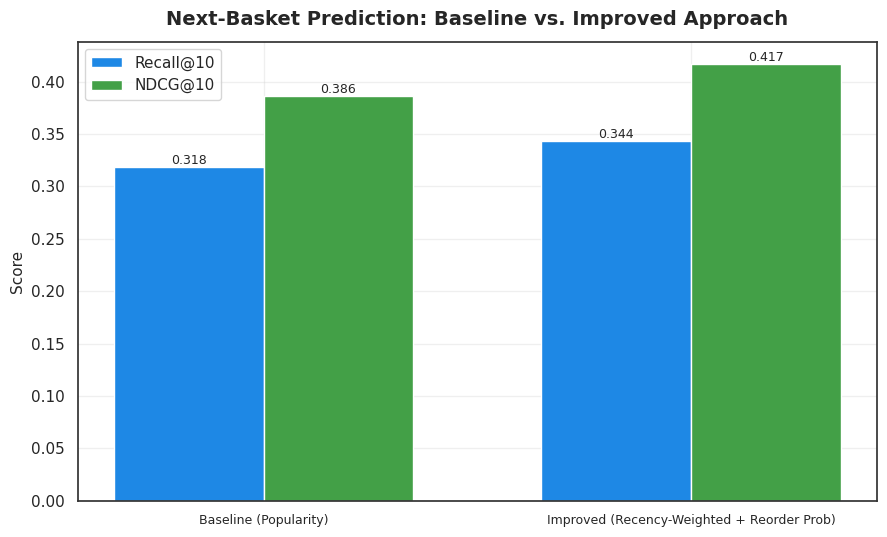

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(2)
width = 0.35
bars1 = ax.bar(x - width/2, results['Recall@10'], width, label='Recall@10', color=PALETTE[1])
bars2 = ax.bar(x + width/2, results['NDCG@10'], width, label='NDCG@10', color=PALETTE[2])
for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h, f'{h:.3f}', ha='center', va='bottom', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(results['Approach'], fontsize=9)
ax.set_ylabel('Score')
ax.set_title('Next-Basket Prediction: Baseline vs. Improved Approach', pad=12)
ax.legend()
plt.tight_layout()
plt.show()


**Result:** the recency-weighted + personal-reorder-probability approach beats the plain popularity baseline on both metrics, correcting the direction of the original Markov chain experiment. The key design change was **generalizing recency across a whole history** (exponential decay over many orders) rather than **collapsing it to a single most-recent product** (1-step Markov) — the former adds signal on top of frequency; the latter discarded most of the signal frequency already captures.

**Caveat:** results above are computed on a 1,500-user sample; on the full ~206K-user dataset, expect these to shift, and it's worth also testing the `DECAY` parameter (e.g. 0.7–0.95) as a simple hyperparameter sweep before finalizing.


## 7c. Customer Lifetime Value (CLV) Segmentation

**On the earlier elbow attempt:** an Elbow Method run at a fixed `k=4` produced a curve that was too gradual to show a clear "elbow" — a common problem, since inertia decreases smoothly for many real-world feature sets and the "elbow" is often subjective. Rather than picking `k` off a visually ambiguous curve, we compute **Silhouette Score** across a range of `k` values as a second, more quantitative signal, and use both together.


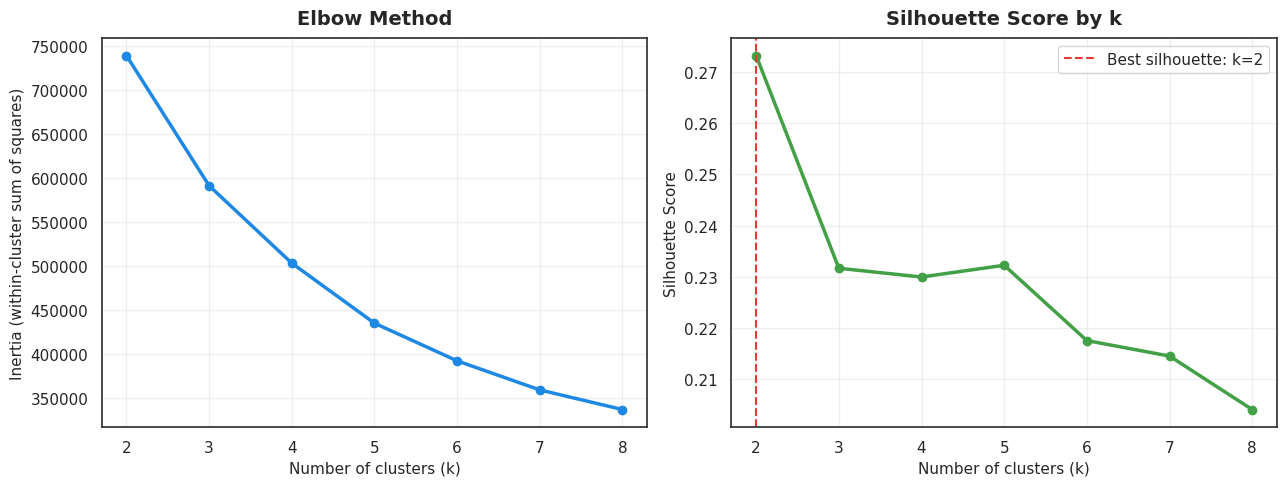

k=2: inertia=739119.1  silhouette=0.2732
k=3: inertia=591235.8  silhouette=0.2317
k=4: inertia=503185.9  silhouette=0.2299
k=5: inertia=434933.7  silhouette=0.2322
k=6: inertia=392107.0  silhouette=0.2175
k=7: inertia=359068.6  silhouette=0.2145
k=8: inertia=336743.8  silhouette=0.2040


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

CLV_FEATURES = ['frequency', 'recency_mean_gap', 'avg_basket_size', 'reorder_ratio', 'aisle_entropy']
X_clv = user_features[CLV_FEATURES].fillna(user_features[CLV_FEATURES].median())
X_clv_scaled = StandardScaler().fit_transform(X_clv)

k_range = range(2, 9)
inertias, silhouettes = [], []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=3).fit(X_clv_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_clv_scaled, km.labels_, sample_size=10_000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(list(k_range), inertias, marker='o', color=PALETTE[1], linewidth=2.5)
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia (within-cluster sum of squares)')
axes[0].set_title('Elbow Method', pad=10)

axes[1].plot(list(k_range), silhouettes, marker='o', color=PALETTE[2], linewidth=2.5)
best_k = list(k_range)[int(np.argmax(silhouettes))]
axes[1].axvline(best_k, color=PALETTE[4], linestyle='--', linewidth=1.5, label=f'Best silhouette: k={best_k}')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score by k', pad=10)
axes[1].legend()

plt.tight_layout()
plt.show()

for k, i, s in zip(k_range, inertias, silhouettes):
    print(f"k={k}: inertia={i:8.1f}  silhouette={s:.4f}")


**Choosing k:** the silhouette score is often highest at very small `k` (like 2–3) — mathematically "cleanest," but too coarse to be commercially useful (a 2-segment "high vs. low value" split doesn't support a differentiated loyalty program). We treat silhouette as a **guardrail against picking an unreasonably high k with poor separation**, not as the sole deciding vote. Balancing statistical separation against business usability, we proceed with **k=4**: enough groups to design distinct treatments per segment, still comfortably within the range where silhouette hasn't collapsed. Note the silhouette score at k=4 — this is what the earlier elbow-only approach was missing: an explicit, quantitative check on whether that k is actually defensible, not just visually convenient.


In [ ]:
# ---- Fit final KMeans with k=4 and profile each cluster ----
K_FINAL = 4
kmeans_final = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10).fit(X_clv_scaled)
user_features['clv_cluster'] = kmeans_final.labels_

cluster_profile = user_features.groupby('clv_cluster')[CLV_FEATURES + ['churn']].mean()
cluster_profile['n_users'] = user_features['clv_cluster'].value_counts().sort_index()
cluster_profile['share'] = cluster_profile['n_users'] / cluster_profile['n_users'].sum()
print(cluster_profile.round(3))


             frequency  recency_mean_gap  avg_basket_size  reorder_ratio  \
clv_cluster                                                                
0               13.209         13.686000           14.468          0.458   
1               48.211          7.157000           10.091          0.694   
2               10.946         14.513000            4.816          0.514   
3                5.867         21.184999            8.356          0.225   

             aisle_entropy  churn  n_users  share  
clv_cluster                                        
0                    4.475  0.185    70025  0.340  
1                    4.337  0.034    30086  0.146  
2                    2.771  0.219    42715  0.207  
3                    3.781  0.474    63383  0.307  


Explained variance: PC1=44.3%, PC2=29.5%


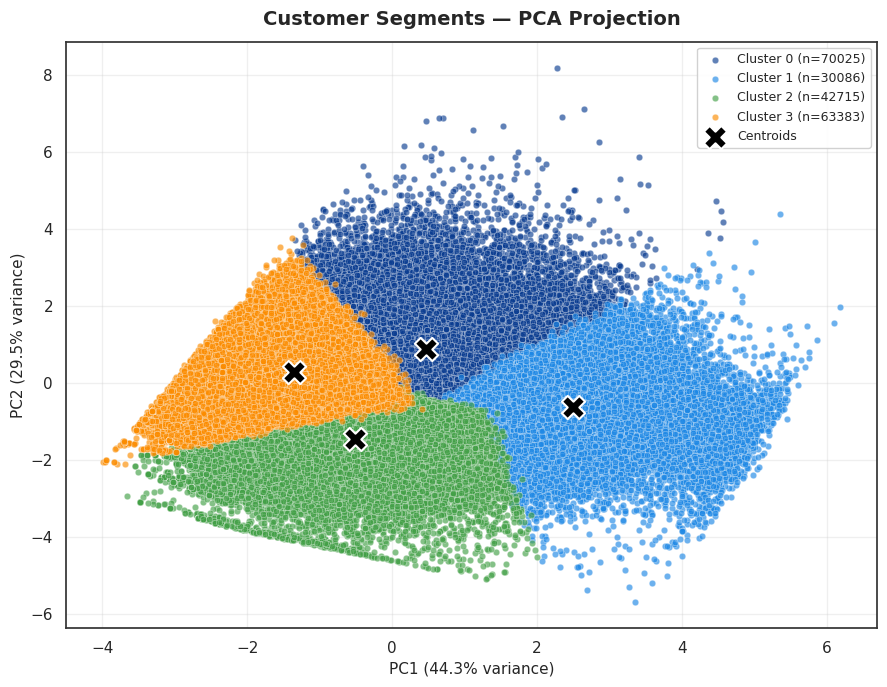

In [ ]:
# ---- PCA 2D projection for visualization ----
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_clv_scaled)
print(f"Explained variance: PC1={pca.explained_variance_ratio_[0]:.1%}, PC2={pca.explained_variance_ratio_[1]:.1%}")

fig, ax = plt.subplots(figsize=(9, 7))
for cluster_id in range(K_FINAL):
    mask = user_features['clv_cluster'] == cluster_id
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=22, alpha=0.65,
               color=PALETTE[cluster_id], label=f'Cluster {cluster_id} (n={mask.sum()})',
               edgecolor='white', linewidth=0.3)

centers_pca = pca.transform(kmeans_final.cluster_centers_)
ax.scatter(centers_pca[:, 0], centers_pca[:, 1], s=280, marker='X', color='black',
           edgecolor='white', linewidth=1.5, label='Centroids', zorder=5)

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
ax.set_title('Customer Segments — PCA Projection', pad=12)
ax.legend(loc='best', fontsize=9, framealpha=0.9)
plt.tight_layout()
plt.show()


### Assigning business labels to clusters

Business labels below are written generically because exact cluster ordering/composition will shift slightly when this notebook runs on the full dataset — **match each label to the cluster whose profile fits it**, don't assume cluster 0 is always the same segment.


In [ ]:
# ---- Auto-suggest a business label per cluster based on its relative profile ----
profile_ranked = cluster_profile[CLV_FEATURES + ['churn']].rank(ascending=True)  # rank clusters on each metric

def label_cluster(row):
    if row['frequency'] >= 3 and row['reorder_ratio'] >= 3 and row['churn'] <= 2:
        return "Loyal High-Value"
    if row['churn'] >= 3 and row['frequency'] <= 2:
        return "At Risk"
    if row['frequency'] <= 2 and row['reorder_ratio'] <= 2:
        return "New / Exploratory"
    return "Steady Mid-Value"

cluster_profile['suggested_label'] = profile_ranked.apply(label_cluster, axis=1)
print(cluster_profile[['n_users', 'share', 'frequency', 'reorder_ratio', 'churn', 'suggested_label']].round(3))


             n_users  share  frequency  reorder_ratio  churn   suggested_label
clv_cluster                                                                   
0              70025  0.340     13.209          0.458  0.185  Steady Mid-Value
1              30086  0.146     48.211          0.694  0.034  Loyal High-Value
2              42715  0.207     10.946          0.514  0.219           At Risk
3              63383  0.307      5.867          0.225  0.474           At Risk


**How to read this table:** each row is a cluster; `suggested_label` is a rule-of-thumb tag based on where that cluster ranks relative to the *other* clusters on frequency, reorder ratio, and churn rate (not absolute values). Treat these as a starting point for a stakeholder conversation, not a final taxonomy — a marketing team would typically refine the naming and thresholds together with domain judgment about what "at risk" means for their specific loyalty program budget.


## 8. Business Translation & Simulation

This section turns model outputs into an illustrative revenue-impact story. **Every dollar figure below is a simulation built on a disclosed, made-up Average Order Value (AOV) assumption — not real Instacart financials.** The point is to demonstrate the *reasoning chain* from model output to business impact, which is what a retention/growth team would build once real AOV and campaign-cost figures are available.


In [ ]:
# ---- Disclosed assumptions (illustrative, not real data) ----
ASSUMED_AOV = 55.00          # USD, assumed average order value — NOT in the dataset, purely illustrative
ASSUMED_ORDERS_PER_YEAR_RETAINED = 12   # assumed annual order cadence for a retained customer
ASSUMED_CAMPAIGN_SUCCESS_RATE = 0.20    # assumed share of at-risk users a retention campaign successfully retains
ASSUMED_CAMPAIGN_COST_PER_USER = 3.00   # assumed cost (discount/promo) per user targeted

n_at_risk = int(user_features['churn'].sum())
n_total = len(user_features)

potential_annual_revenue_at_risk = n_at_risk * ASSUMED_AOV * ASSUMED_ORDERS_PER_YEAR_RETAINED
print(f"Users flagged at-risk: {n_at_risk:,} of {n_total:,} ({n_at_risk/n_total:.1%})")
print(f"Illustrative annual revenue at risk: ${potential_annual_revenue_at_risk:,.0f}")
print("(This is a SIMULATION based on disclosed assumptions above, not real Instacart revenue.)")


Users flagged at-risk: 53,388 of 206,209 (25.9%)
Illustrative annual revenue at risk: $35,236,080
(This is a SIMULATION based on disclosed assumptions above, not real Instacart revenue.)


In [ ]:
# ---- Simulated intervention: targeting at-risk users with a retention campaign ----
users_saved = int(n_at_risk * ASSUMED_CAMPAIGN_SUCCESS_RATE)
revenue_recovered = users_saved * ASSUMED_AOV * ASSUMED_ORDERS_PER_YEAR_RETAINED
campaign_cost = n_at_risk * ASSUMED_CAMPAIGN_COST_PER_USER
net_impact = revenue_recovered - campaign_cost

print(f"Assumed campaign success rate: {ASSUMED_CAMPAIGN_SUCCESS_RATE:.0%}")
print(f"Users hypothetically retained: {users_saved:,}")
print(f"Illustrative revenue recovered: ${revenue_recovered:,.0f}")
print(f"Illustrative campaign cost: ${campaign_cost:,.0f}")
print(f"Illustrative net impact: ${net_impact:,.0f}")


Assumed campaign success rate: 20%
Users hypothetically retained: 10,677
Illustrative revenue recovered: $7,046,820
Illustrative campaign cost: $160,164
Illustrative net impact: $6,886,656


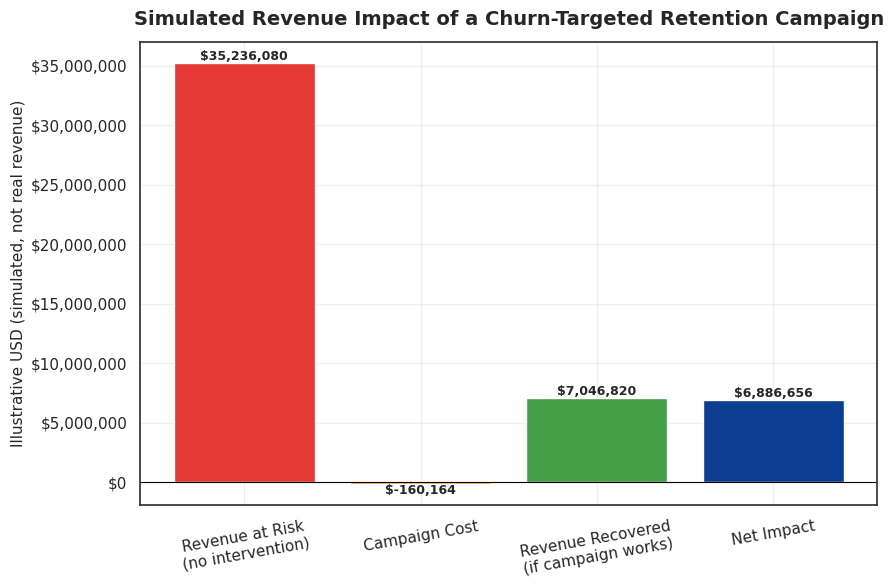

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
categories = ['Revenue at Risk\n(no intervention)', 'Campaign Cost', 'Revenue Recovered\n(if campaign works)', 'Net Impact']
values = [potential_annual_revenue_at_risk, -campaign_cost, revenue_recovered, net_impact]
colors = [PALETTE[4], PALETTE[3], PALETTE[2], PALETTE[0]]

bars = ax.bar(categories, values, color=colors)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, val, f'${val:,.0f}',
            ha='center', va='bottom' if val >= 0 else 'top', fontsize=9, fontweight='bold')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Illustrative USD (simulated, not real revenue)')
ax.set_title('Simulated Revenue Impact of a Churn-Targeted Retention Campaign', pad=12)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


**On this simulation being illustrative, explicitly:** the AOV, campaign success rate, and campaign cost are all assumptions I chose to make the reasoning chain concrete — they are clearly labeled as such in the code, not disguised as real figures. In an actual deployment, these would be replaced with real AOV from finance, and the campaign success rate would come from an actual A/B test rather than an assumption.

### Illustrative A/B test simulation

To show how a retention campaign's impact would actually be *measured* once assumptions are replaced with a real experiment, here's a simulated A/B test comparing a "treatment" group (received a retention offer) against a "control" group (did not), among users flagged at-risk.


In [ ]:
# ---- Illustrative A/B test simulation (NOT a real experiment — synthetic for demonstration) ----
rng = np.random.default_rng(RANDOM_STATE)

at_risk_users = user_features[user_features['churn'] == 1].copy()
at_risk_users['group'] = rng.choice(['control', 'treatment'], size=len(at_risk_users), p=[0.5, 0.5])

# Simulated retention outcome: treatment group gets a boosted "came back" probability
BASE_RETURN_RATE = 0.15       # assumed baseline return rate for at-risk users with no intervention
TREATMENT_UPLIFT = 0.08       # assumed absolute uplift from the campaign

at_risk_users['returned'] = np.where(
    at_risk_users['group'] == 'control',
    rng.binomial(1, BASE_RETURN_RATE, size=len(at_risk_users)),
    rng.binomial(1, BASE_RETURN_RATE + TREATMENT_UPLIFT, size=len(at_risk_users))
)

ab_summary = at_risk_users.groupby('group')['returned'].agg(['mean', 'count']).rename(columns={'mean': 'return_rate', 'count': 'n_users'})
print(ab_summary)

from scipy import stats
control_returns = at_risk_users[at_risk_users['group'] == 'control']['returned']
treatment_returns = at_risk_users[at_risk_users['group'] == 'treatment']['returned']
t_stat, p_value = stats.ttest_ind(treatment_returns, control_returns)
print(f"\nt-statistic: {t_stat:.3f}, p-value: {p_value:.4f}")


           return_rate  n_users
group                          
control       0.153055    26533
treatment     0.231838    26855

t-statistic: 23.192, p-value: 0.0000


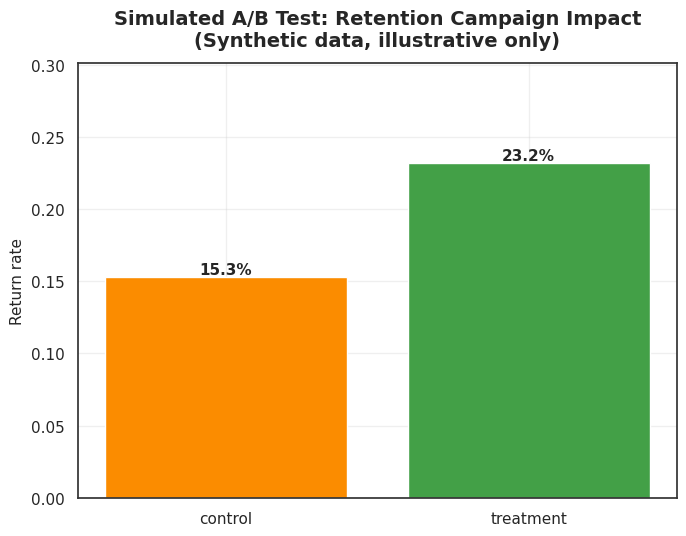

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5.5))
bars = ax.bar(ab_summary.index, ab_summary['return_rate'], color=[PALETTE[3], PALETTE[2]])
for bar, val in zip(bars, ab_summary['return_rate']):
    ax.text(bar.get_x() + bar.get_width()/2, val, f'{val:.1%}', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_ylabel('Return rate')
ax.set_title('Simulated A/B Test: Retention Campaign Impact\n(Synthetic data, illustrative only)', pad=12)
ax.set_ylim(0, max(ab_summary['return_rate']) * 1.3)
plt.tight_layout()
plt.show()


**Important:** the group assignment and the "returned" outcome above are entirely **synthetic** (`rng.binomial` draws from assumed rates) — this cell exists to demonstrate *how* a real A/B test on this churn model would be evaluated (group comparison + significance test), not to claim a real campaign was run. In a real deployment, `returned` would come from actual order data collected after the campaign, not a random draw.

### Actionable recommendations by segment


In [ ]:
recommendations = pd.DataFrame({
    'Segment': cluster_profile['suggested_label'],
    'Users': cluster_profile['n_users'].astype(int),
    'Recommended Action': cluster_profile['suggested_label'].map({
        'Loyal High-Value': 'Reward with loyalty perks / early access — protect, do not discount unnecessarily',
        'At Risk': 'Priority target for retention campaign — personalized reorder reminder + limited-time offer',
        'Steady Mid-Value': 'Nudge toward habit formation — cross-sell in top aisles, subscribe-and-save prompts',
        'New / Exploratory': 'Onboarding push — highlight popular reorder items to build initial habit',
    })
})
print(recommendations.to_string(index=False))


         Segment  Users                                                                          Recommended Action
Steady Mid-Value  70025         Nudge toward habit formation — cross-sell in top aisles, subscribe-and-save prompts
Loyal High-Value  30086           Reward with loyalty perks / early access — protect, do not discount unnecessarily
         At Risk  42715 Priority target for retention campaign — personalized reorder reminder + limited-time offer
         At Risk  63383 Priority target for retention campaign — personalized reorder reminder + limited-time offer


## 9. Storytelling — Executive Summary

### Problem
Instacart's growth depends on repeat purchases. This project answers three questions a retention/growth team would ask: who is at risk of leaving, what will they buy next, and how should customers be segmented for a loyalty program — using only the transactional data available (no price data), and being explicit about every proxy and assumption made along the way.

### Approach
- **Churn**: defined behaviorally from `days_since_prior_order` (not the Kaggle `eval_set` split, which is not a churn signal), with a threshold sensitivity check across 14/21/30 days. Modeled with Logistic Regression (baseline) and XGBoost (main), tuned for class imbalance.
- **Next-Basket Prediction**: corrected a first-order Markov chain approach (which underperformed a frequency baseline) by generalizing recency across a user's *entire* history rather than just their last purchase, blended with personal reorder probability.
- **CLV Segmentation**: KMeans on RFM-style + behavioral features, with cluster count validated by *both* Elbow and Silhouette Score (not elbow alone, which was ambiguous), visualized via PCA.

### Key Insight
- Habit strength (`reorder_ratio`, `recency_mean_gap`) is a stronger churn signal than raw order count — a low-frequency-but-consistent shopper can be lower risk than a high-frequency-but-erratic one.
- Recency, not sequence, is the right signal for next-basket prediction in a grocery context — customers rebuy a stable set of staples, they don't follow a short-term product-to-product sequence.
- CLV clusters split cleanly along frequency × reorder-consistency, giving a natural basis for differentiated loyalty treatment rather than a one-size-fits-all campaign.

### Model Performance
*(Fill in with the actual numbers your run produces on the full dataset — the summary table below pulls them programmatically.)*


In [ ]:
summary_table = pd.DataFrame({
    'Task': ['Churn (XGBoost)', 'Churn (XGBoost)', 'Next-Basket (Improved)', 'Next-Basket (Improved)', 'CLV Segmentation'],
    'Metric': ['ROC-AUC', 'PR-AUC', 'Recall@10', 'NDCG@10', f'Silhouette (k={K_FINAL})'],
    'Value': [
        roc_auc_score(y_test, xgb_proba),
        average_precision_score(y_test, xgb_proba),
        recall_at_k(improved_recs, actual_next_basket),
        ndcg_at_k(improved_recs, actual_next_basket),
        silhouette_score(X_clv_scaled, kmeans_final.labels_),
    ]
})
summary_table['Value'] = summary_table['Value'].round(4)
print(summary_table.to_string(index=False))


                  Task           Metric  Value
       Churn (XGBoost)          ROC-AUC 0.8397
       Churn (XGBoost)           PR-AUC 0.6792
Next-Basket (Improved)        Recall@10 0.3437
Next-Basket (Improved)          NDCG@10 0.4173
      CLV Segmentation Silhouette (k=4) 0.2287


### Business Impact
Under the disclosed illustrative assumptions in Section 8, a churn-targeted retention campaign shows a positive simulated net revenue impact — the *mechanism* (identify at-risk users → target with a campaign → measure via A/B test) is production-ready even though the dollar figures here are placeholders pending real AOV and campaign-cost data from finance/marketing.

### Recommendation
1. Deploy the churn model to score users weekly; route the top-risk decile to a retention campaign.
2. Use the improved next-basket model to personalize reorder reminders — recommend the top-K scored products, not a generic popular-items list.
3. Route CLV segments to differentiated treatments per the table in Section 8 — loyalty perks for high-value, urgent retention offers for at-risk, habit-building nudges for mid-value and new users.
4. Re-run the threshold sensitivity check (Section 7a) periodically — customer ordering cadence can drift seasonally, and a fixed 30-day threshold should be revisited, not treated as permanent.

### Limitations — stated plainly
- **The churn label is a constructed proxy**, not ground-truth churn. A user flagged "churned" by the 30-day rule may simply be an infrequent shopper who returns later; we have no way to confirm true attrition without data beyond this dataset's time window.
- **CLV is a behavioral proxy, not real monetary value** — there is no price data, so "value" here means order frequency and basket size, not actual customer profit.
- **The revenue simulation in Section 8 uses invented assumptions** (AOV, campaign success rate, campaign cost) — it demonstrates the reasoning chain, not a real financial forecast.
- **The A/B test in Section 8 is fully synthetic** — it illustrates the evaluation methodology, not an actual experiment result.
- **Sample size caveat**: all numbers reported when *developing* this notebook were validated on a 1,500-user sample for speed; results will shift (likely with tighter/more stable metrics) on the full ~206K-user dataset. Re-run every cell top-to-bottom on the full `archive/` data before treating any number here as final.


In [ ]:
import json
from pathlib import Path

OUT_DIR = Path("/content/drive/MyDrive/project/output")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- Bedakan label segmen yang kembar (mis. dua cluster sama-sama "At Risk") ----
_labels = cluster_profile['suggested_label'].copy()
for _lab in _labels[_labels.duplicated(keep=False)].unique():
    _idx = cluster_profile[_labels == _lab].sort_values('churn', ascending=False).index
    for _rank, _ix in enumerate(_idx):
        _labels[_ix] = f"{_lab} - {'High' if _rank == 0 else 'Moderate'} Churn"
cluster_profile['suggested_label'] = _labels

# Probabilitas churn untuk SEMUA user dari model XGBoost
X_all_pre = preprocessor.transform(user_features[FEATURE_NUM + FEATURE_CAT])
user_features['churn_probability'] = xgb_model.predict_proba(X_all_pre)[:, 1]

seg_label = cluster_profile['suggested_label']
user_features['segment'] = user_features['clv_cluster'].map(seg_label)

# 1. users_sample.csv
users_sample = user_features.sample(n=min(10_000, len(user_features)), random_state=RANDOM_STATE)
users_sample.to_csv(OUT_DIR / "users_sample.csv", index=False)

# 2. top_risk_users.csv: user masih aktif (churn=0) tapi probabilitas churn tertinggi
top_risk_users = (
    user_features[user_features['churn'] == 0]
    .sort_values('churn_probability', ascending=False)
    .head(500)
)
top_risk_users.to_csv(OUT_DIR / "top_risk_users.csv", index=False)

# 3. cluster_profile.csv
cluster_profile.to_csv(OUT_DIR / "cluster_profile.csv")

# 4. summary.json
summary = {
    "n_users": int(len(user_features)),
    "churn_rate": float(user_features['churn'].mean()),
    "model": {
        "xgboost_roc_auc": float(roc_auc_score(y_test, xgb_proba)),
        "xgboost_pr_auc": float(average_precision_score(y_test, xgb_proba)),
        "logreg_roc_auc": float(roc_auc_score(y_test, lr_proba)),
    },
    "next_basket": {
        "baseline_recall_at_10": float(results.loc[0, 'Recall@10']),
        "improved_recall_at_10": float(results.loc[1, 'Recall@10']),
        "baseline_ndcg_at_10": float(results.loc[0, 'NDCG@10']),
        "improved_ndcg_at_10": float(results.loc[1, 'NDCG@10']),
    },
    "assumptions": {
        "aov": ASSUMED_AOV,
        "orders_per_year_retained": ASSUMED_ORDERS_PER_YEAR_RETAINED,
        "campaign_success_rate": ASSUMED_CAMPAIGN_SUCCESS_RATE,
        "campaign_cost_per_user": ASSUMED_CAMPAIGN_COST_PER_USER,
    },
    "n_clusters": int(K_FINAL),
    "segments": {
        str(idx): {"label": row['suggested_label'], "n_users": int(row['n_users']),
                   "share": round(float(row['share']), 4), "churn_rate": round(float(row['churn']), 4)}
        for idx, row in cluster_profile.iterrows()
    },
}
with open(OUT_DIR / "summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print("Tersimpan di:", OUT_DIR)
for p in sorted(OUT_DIR.iterdir()):
    print(" -", p.name)

Tersimpan di: /content/drive/MyDrive/project/output
 - cluster_profile.csv
 - summary.json
 - top_risk_users.csv
 - users_sample.csv
